# Pay-Equity Audit with Supervised Learning

**Course:** Supervised Learning & Model Engineering, Ilana SEBAG

**Team:** Thomas Pasquier--Guillard, Lélia Hervy, Robin Cacarié

**Dataset:** Adult / Census Income (OpenML `adult`, version 2)

### Our role: a government pay-equity regulator

We play the role of a **government agency** that checks whether employers pay people **fairly with respect to gender and race**. The guiding principle is **"equal pay for equal work"**: two people with the same qualifications, job, working time and experience should have the same chance of a high salary, whatever their sex or race.

We build a **reference pay model**: it estimates the probability of earning more than \$50K **from legitimate, job-related factors only**. The audit then compares, for each group, the **actual** share of high earners with the share the model **expects** from their qualifications. A group that earns systematically less than expected is a warning sign that justifies an investigation.

## Setup

In [1]:
%pip install -q scikit-learn pandas matplotlib mlflow lightgbm imbalanced-learn optuna shap fairlearn fastapi uvicorn httpx

In [2]:
import os
import sys
import json
import time
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
import optuna
import shap
import cloudpickle

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline   # a Pipeline that accepts resampling steps
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    equal_opportunity_difference,
    equalized_odds_difference,
)

RANDOM_STATE = 42
TARGET = "income_over_50k"

pd.set_option("display.max_columns", 50)
set_config(display="diagram")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

### Graphic identity of the agency

- **series colours**, always in this order: navy, sky blue, teal, violet;
- **greys** for reference elements (baselines, "random model", the "before" model), axes and text;
- a **single-hue blue scale** (pale → navy) for magnitudes, such as confusion matrices.

In [3]:
# ---- Graphic identity: blues and greys ----
import matplotlib as mpl
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

NAVY, SKY, TEAL, VIOLET = "#1C5AA3", "#74B9EE", "#00927F", "#8170D8"   # series colours, in this order
STEEL, SILVER, INK = "#5F6B7A", "#C5CDD6", "#2B2F36"                   # greys: reference lines, axes, text
SERIES_COLORS = [NAVY, SKY, TEAL, VIOLET]

BLUES = LinearSegmentedColormap.from_list("agency_blues", ["#EEF3F9", NAVY])   # light -> dark, for magnitudes
mpl.colormaps.register(BLUES, force=True)

plt.rcParams.update({
    "axes.prop_cycle": cycler(color=SERIES_COLORS),
    "image.cmap": "agency_blues",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": SILVER,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": INK,
    "xtick.color": STEEL,
    "ytick.color": STEEL,
    "legend.frameon": False,
    "lines.linewidth": 2,
    "patch.edgecolor": "white",
})

# SHAP plots: navy = pushes towards >50K, violet = pushes towards <=50K
try:
    from shap.plots._style import set_style
    set_style(
        primary_color_positive=NAVY, primary_color_negative=VIOLET,
        secondary_color_positive="#8FB0D9", secondary_color_negative="#C3B9EE",
        hlines_color="#E3E8EE", vlines_color=SILVER, tick_labels_color=STEEL,
    )
except ImportError:
    print("Older shap version: SHAP plots keep their default colours.")

# Part 1 — Data, Features, Pipeline and Baseline

## Dataset presentation

The Adult dataset comes from the **1994 US Census**. Each row describes **one adult person**.

The supervised-learning task is **binary classification**: predict whether the person earns **more than \$50K per year**.

$$
Y =
\begin{cases}
1 & \text{income} > 50\text{K}\\
0 & \text{income} \le 50\text{K}
\end{cases}
$$

The 14 predictors are:

- **numeric:** `age`, `fnlwgt` (census sampling weight), `education-num` (education level as a number), `capital-gain`, `capital-loss`, `hours-per-week`;
- **categorical:** `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`.

The modelling question is:

> **Given only a person's job-related profile (education, occupation, working time, experience…), how well can we estimate their probability of earning more than \$50K?**

### Sensitive attributes

`sex` and `race` are **protected attributes**: pay must not depend on them. They are therefore **not inputs of the model**, but we keep them aside because the audit needs them to compare groups.

In [4]:
# Download the dataset from OpenML
adult = fetch_openml(name="adult", version=2, as_frame=True)

X_raw = adult.data.copy()
y_raw = adult.target.copy()

print("Feature matrix shape:", X_raw.shape)
print("Target values:", y_raw.unique().tolist())

Feature matrix shape: (48842, 14)
Target values: ['<=50K', '>50K']


### Encode the target

The target is stored as text (`'>50K'` / `'<=50K'`). Models need numbers, so we convert it to `1` / `0`.

In [5]:
X = X_raw.copy()
y = (y_raw.astype(str).str.strip() == ">50K").astype(int).rename(TARGET)

df = pd.concat([X, y], axis=1)

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income_over_50k
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,1
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,0


## Exploratory Data Analysis

Before fitting a model, we want to understand:
1. what one row represents and the size of the data;
2. the target distribution (class imbalance);
3. missing values and duplicates;
4. the distributions of numeric features;
5. which features are related to the target;
6. which columns are redundant or not meaningful.

### First inspection

In [6]:
def basic_summary(df):
    return {
        "n_rows": df.shape[0],
        "n_columns": df.shape[1],
        "n_missing": int(df.isna().sum().sum()),
        "n_duplicates": int(df.duplicated().sum()),
        "target_rate": float(df[TARGET].mean()),
    }

basic_summary(df)

{'n_rows': 48842,
 'n_columns': 15,
 'n_missing': 6465,
 'n_duplicates': 52,
 'target_rate': 0.23928176569346055}

#### Column types and descriptive statistics

In [7]:
numeric_cols = X.select_dtypes("number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns    :", numeric_cols)
print("Categorical columns:", categorical_cols)

print("\nData types:")
display(df.dtypes)

print("\nDescriptive statistics (numeric):")
display(df[numeric_cols].describe().T)

print("\nNumber of categories per categorical column:")
display(X[categorical_cols].nunique().sort_values(ascending=False))

Numeric columns    : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Data types:


,0
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category



Descriptive statistics (numeric):


,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0



Number of categories per categorical column:


,0
native-country,41
education,16
occupation,14
workclass,8
marital-status,7
relationship,6
race,5
sex,2


**Observation.**
`native-country` has many categories (around 40), most of them very rare: one-hot encoding every country would create many almost-empty columns, so we will group rare categories. The numeric features have very different scales (`age` is in tens, `capital-gain` goes up to 99,999), which matters for Logistic Regression.

We also check duplicates: a few rows are identical. In census data this is plausible (two people with the same profile), so we keep them.

### Explore the target

Share of people earning >50K: 23.93%


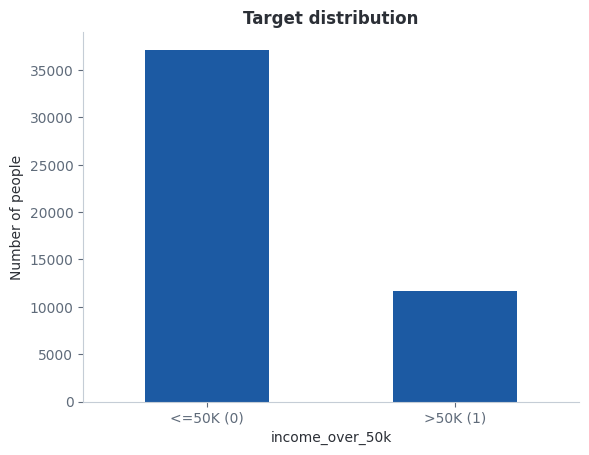

In [8]:
def plot_target_distribution(y):
    counts = y.value_counts().sort_index()
    print(f"Share of people earning >50K: {y.mean():.2%}")

    counts.plot(kind="bar")
    plt.xticks([0, 1], ["<=50K (0)", ">50K (1)"], rotation=0)
    plt.ylabel("Number of people")
    plt.title("Target distribution")
    plt.show()

plot_target_distribution(y)

**Is the dataset balanced? Is accuracy enough to evaluate a model?**

No. Only about **24%** of people earn more than \$50K, so the dataset is imbalanced. A model that always predicts "<=50K" would already reach about **76% accuracy** while being useless. We will therefore focus on **precision, recall, F1, ROC-AUC and PR-AUC**, which look at how well the positive class is detected.

### Missing values

In [9]:
def missing_summary(df):
    missing = df.isna().sum()
    table = pd.DataFrame({
        "n_missing": missing,
        "pct_missing": (missing / len(df) * 100).round(2),
    })
    return table[table["n_missing"] > 0].sort_values("n_missing", ascending=False)

missing_summary(df)

,n_missing,pct_missing
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75


In [10]:
# Are workclass and occupation missing for the same people?
pd.crosstab(
    df["workclass"].isna(),
    df["occupation"].isna(),
    rownames=["workclass missing"],
    colnames=["occupation missing"],
)

occupation missing,False,True
workclass missing,,
False,46033,10
True,0,2799


In [11]:
# Does missingness tell us something about income?
for col in ["workclass", "occupation", "native-country"]:
    rate_missing = df.loc[df[col].isna(), TARGET].mean()
    rate_known = df.loc[df[col].notna(), TARGET].mean()
    print(f"{col:15s} | >50K rate when missing: {rate_missing:.2%} | when known: {rate_known:.2%}")

workclass       | >50K rate when missing: 9.47% | when known: 24.81%
occupation      | >50K rate when missing: 9.43% | when known: 24.81%
native-country  | >50K rate when missing: 25.67% | when known: 23.90%


**How should we handle the missing values?**

Only three categorical columns have missing values (`workclass`, `occupation`, `native-country`), each for a few percent of rows. When `workclass` is missing, `occupation` is almost always missing too, which suggests these people are often not in regular employment. The >50K rate is also **much lower** when `workclass`/`occupation` are missing (about 10% vs 25%), while for `native-country` it makes almost no difference. So missingness is **informative**: instead of guessing a value (e.g. the most frequent category), we replace missing values by a separate category **"Missing"** that the model can learn from. Dropping these rows would throw away information and bias the sample.

### Explore numeric predictors

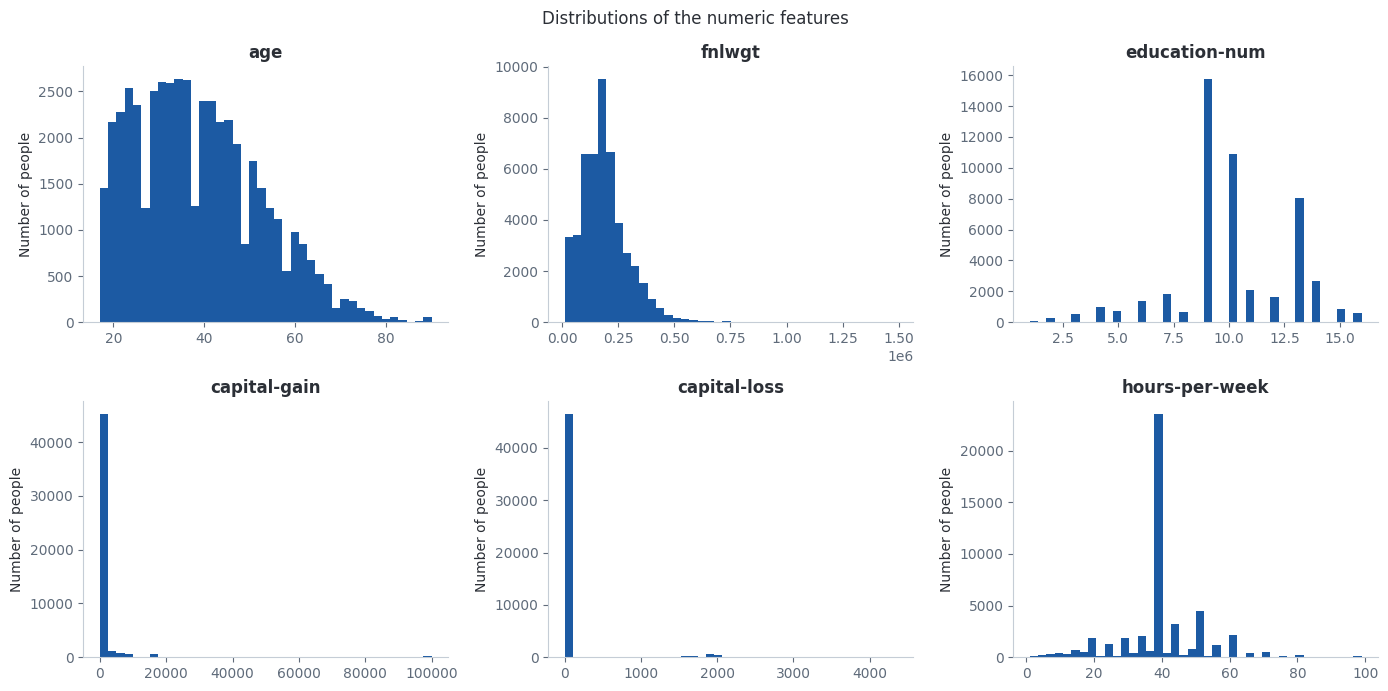

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(df[col], bins=40)
    ax.set_title(col)
    ax.set_ylabel("Number of people")

plt.suptitle("Distributions of the numeric features")
plt.tight_layout()
plt.show()

In [13]:
for col in ["capital-gain", "capital-loss"]:
    print(f"{col}: {(df[col] == 0).mean():.1%} of people have exactly 0, max = {df[col].max():,}")

capital-gain: 91.7% of people have exactly 0, max = 99,999
capital-loss: 95.3% of people have exactly 0, max = 4,356


**Observation.**
`capital-gain` and `capital-loss` are **extremely skewed**: over 90% of people have exactly 0, and a few have very large values (the maximum 99,999 is a cap used in the census). For a linear model, a raw value of 99,999 would dominate everything. This motivates two engineered features: a **log transform** of capital gain and a **"has any capital" flag**.

### Which features are related to income?


Complete `rate_by_group` so that it returns, for each value of a feature, the number of people and the share earning >50K.

In [14]:
def rate_by_group(df, feature):
    return (
        df.groupby(feature, observed=True)[TARGET]
        .agg(n_people="size", rate_over_50k="mean")
        .sort_values("rate_over_50k", ascending=False)
    )

In [15]:
for feature in ["marital-status", "relationship", "education-num"]:
    print(f"\n=== {feature} ===")
    display(rate_by_group(df, feature).round(3))


=== marital-status ===


,n_people,rate_over_50k
marital-status,,
Married-civ-spouse,22379,0.446
Married-AF-spouse,37,0.378
Divorced,6633,0.101
Married-spouse-absent,628,0.092
Widowed,1518,0.084
Separated,1530,0.065
Never-married,16117,0.045



=== relationship ===


,n_people,rate_over_50k
relationship,,
Wife,2331,0.469
Husband,19716,0.449
Not-in-family,12583,0.101
Unmarried,5125,0.060
Other-relative,1506,0.035
Own-child,7581,0.015



=== education-num ===


,n_people,rate_over_50k
education-num,,
15,834,0.740
16,594,0.726
14,2657,0.549
13,8025,0.413
12,1601,0.258
11,2061,0.253
10,10878,0.190
9,15784,0.159
8,657,0.073


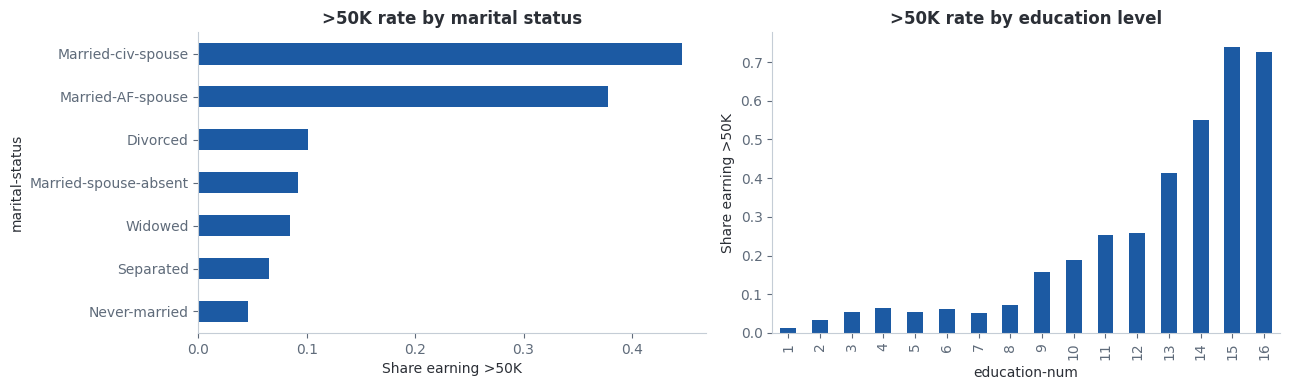

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

rate_by_group(df, "marital-status")["rate_over_50k"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title(">50K rate by marital status")
axes[0].set_xlabel("Share earning >50K")

rate_by_group(df, "education-num")["rate_over_50k"].sort_index().plot.bar(ax=axes[1])
axes[1].set_title(">50K rate by education level")
axes[1].set_xlabel("education-num")
axes[1].set_ylabel("Share earning >50K")

plt.tight_layout()
plt.show()

**Observation.**
- **Marital status** is very discriminative: people in the `Married-civ-spouse` category earn >50K far more often (around 45%) than never-married people (around 5%). Part of this is age (married people are older) and household structure, not marriage itself.
- **Education level** increases the >50K rate almost monotonically: higher `education-num` → higher income rate.

These are **associations**, not causal effects: the table does not prove that getting married raises income.

### Sensitive attributes: `sex` and `race`

In [17]:
for feature in ["sex", "race"]:
    print(f"\n=== {feature} ===")
    display(rate_by_group(df, feature).round(3))


=== sex ===


,n_people,rate_over_50k
sex,,
Male,32650,0.304
Female,16192,0.109



=== race ===


,n_people,rate_over_50k
race,,
Asian-Pac-Islander,1519,0.269
White,41762,0.254
Other,406,0.123
Black,4685,0.121
Amer-Indian-Eskimo,470,0.117


**What do these tables tell the regulator?**

They show the **raw pay gap**: men earn >50K roughly **three times as often** as women (about 30% vs 11%), and White and Asian-Pac-Islander people about twice as often as Black, Amer-Indian-Eskimo and "Other" people. A raw gap alone does **not** prove unfair pay: groups may differ in education, occupation or working hours. The regulator's real question is whether the gap remains **between comparable people**.

### Does the gap remain between comparable people?


We compare men and women **with the same education level**.

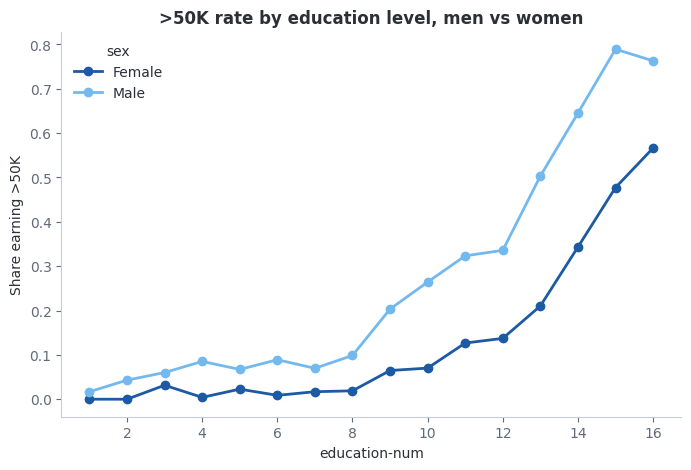

sex,Female,Male
education-num,,
9,0.065,0.203
10,0.070,0.264
13,0.210,0.503
14,0.343,0.645


In [18]:
rate_by_education_and_sex = (
    df.groupby(["education-num", "sex"], observed=True)[TARGET]
    .mean()
    .unstack()
)

rate_by_education_and_sex.plot(marker="o", figsize=(8, 5))
plt.xlabel("education-num")
plt.ylabel("Share earning >50K")
plt.title(">50K rate by education level, men vs women")
plt.show()

rate_by_education_and_sex.loc[[9, 10, 13, 14]].round(3)

In [19]:
# Same comparison inside the most common occupations
top_occupations = df["occupation"].value_counts().head(6).index
(
    df[df["occupation"].isin(top_occupations)]
    .groupby(["occupation", "sex"], observed=True)[TARGET]
    .mean()
    .unstack()
    .round(3)
)

sex,Female,Male
occupation,,
Adm-clerical,0.082,0.249
Craft-repair,0.102,0.233
Exec-managerial,0.241,0.573
Other-service,0.029,0.057
Prof-specialty,0.260,0.560
Sales,0.069,0.377


**Does the gap disappear when we compare people with the same education or occupation?**

No. At **every** education level, women earn >50K much less often than men: for example, among people with a Bachelor's degree (`education-num` = 13) about 21% of women vs 50% of men, and among high-school graduates (9) about 7% vs 20%. The gap also remains inside each occupation: for example about 24% vs 57% among executives/managers and 7% vs 38% in sales. Part of this may still be explained by other legitimate factors (women work fewer hours on average, are younger in this sample, work in different industries…), which is why we need a **model that controls for all job-related factors at once**. That is the reference pay model built in this project.

### Which columns may the reference model use?

For a pay-equity audit, the choice of input columns is a **policy decision**, not only a statistical one. A column is allowed only if it is a **legitimate, job-related reason** for a pay difference.

#### Is `relationship` a proxy for sex?

In [20]:
pd.crosstab(df["relationship"], df["sex"])

sex,Female,Male
relationship,,
Husband,1,19715
Not-in-family,5870,6713
Other-relative,689,817
Own-child,3376,4205
Unmarried,3928,1197
Wife,2328,3


**Observation.**
`Husband` is (almost) always `Male` and `Wife` is (almost) always `Female`: the `relationship` column **encodes sex**. A model that used it could learn the gender pay gap through the back door, even without the `sex` column.

#### Redundant and meaningless columns

Check whether `education` and `education-num` contain the same information, and whether `fnlwgt` is related to income.

In [21]:
# Each education label should map to exactly one education-num value
education_map = df.groupby("education", observed=True)["education-num"].nunique()
print("Max number of education-num values per education label:", education_map.max())

df.groupby("education", observed=True)["education-num"].first().sort_values()

Max number of education-num values per education label: 1


,education-num
education,
Preschool,1
1st-4th,2
5th-6th,3
7th-8th,4
9th,5
10th,6
11th,7
12th,8
HS-grad,9


In [22]:
# fnlwgt: >50K rate across 10 equal-sized groups (deciles) of fnlwgt
fnlwgt_deciles = pd.qcut(df["fnlwgt"], q=10)
df.groupby(fnlwgt_deciles, observed=True)[TARGET].mean().round(3)

,income_over_50k
fnlwgt,
"(12284.999, 65738.2]",0.216
"(65738.2, 106072.2]",0.246
"(106072.2, 130714.0]",0.254
"(130714.0, 157932.0]",0.252
"(157932.0, 178144.5]",0.252
"(178144.5, 196308.0]",0.252
"(196308.0, 220148.0]",0.235
"(220148.0, 260254.0]",0.223
"(260254.0, 328466.0]",0.223


### Decision: the columns of the reference pay model

| Column(s) | Decision | Reason |
|---|---|---|
| `age` | **use** | proxy for work experience, a legitimate pay factor |
| `education-num` | **use** | qualification level |
| `occupation`, `workclass` | **use** | the job itself and the type of employer ("equal work") |
| `hours-per-week` | **use** | working time: part-time work legitimately pays less per year |
| `capital-gain`, `capital-loss` | **use as controls** | the target is *total* income: investment income is not paid by the employer, so we must account for it so it is not mistaken for a pay gap |
| `sex`, `race` | **exclude** (kept for the audit) | protected attributes: pay must not depend on them |
| `native-country` | **exclude** | national origin is also a protected characteristic |
| `relationship` | **exclude** | encodes sex (see the crosstab above) |
| `marital-status` | **exclude** | not job-related, and protected in many anti-discrimination laws; marriage is associated with higher pay for men but not for women |
| `education` | **exclude** | duplicate of `education-num` (text version) |
| `fnlwgt` | **exclude** | census sampling weight: the >50K rate stays between roughly 22% and 26% across its deciles, with no clear trend |

Excluding marital status and relationship removes some predictive power (they were among the strongest predictors in the exploration above). That is **intended**: a reference model that used them would treat part of the discrimination as "normal" and hide it from the audit. We will measure this trade-off in Part 4.

### Leakage audit: could we know each column at prediction time?

The course asks every feature to pass one test: *could I genuinely know this value at the moment the prediction is made, without it containing the answer?*

| Column(s) | Known before the prediction? | Leakage risk | Comment |
|---|---|---|---|
| `age`, `education-num`, `workclass`, `occupation`, `hours-per-week` | yes | low | describe the person and the job, not the income |
| `capital-gain`, `capital-loss` | yes (same year) | **medium: partial target leakage** | the target is **total** income, and investment income is **part of it**: a large capital gain can push someone above \$50K by itself. We keep these columns **on purpose**, as controls, so that non-wage income is not mistaken for pay set by the employer. Consequence: predictive scores are somewhat higher than with job information alone. Part 4 checks that the audit's conclusion does not depend on them. |
| `fnlwgt` | yes | none, but meaningless | survey sampling weight, dropped |
| `income_over_50k` | no | target | never used as an input |

**What we cannot check.** The census is one cross-section with no dates, so there is no temporal leakage to audit, and no person identifier, so we cannot detect the same person appearing twice (group leakage). The 52 duplicated rows are plausible different people with identical profiles; even if a few were the same person, their effect on a 48,842-row dataset is negligible.

## Train / Validation / Test Split

We need **three** sets:

- **train (60%)**: used to fit the models;
- **validation (20%)**: used to compare models and choices during development;
- **test (20%)**: locked away and used **only once at the end** (final evaluation and fairness audit).

Why not just train/test? Every time we look at a score and change something, we adapt our choices to that data. If we did this on the test set, the final test score would be **optimistic**. The validation set absorbs this. (Later, Optuna tuning will use **cross-validation** inside the training set.)

We use `stratify` so that every set keeps the same ~24% share of positives, and `random_state=42` for reproducibility.

### Create the split

In [23]:
def make_train_val_test_split(X, y, test_size=0.20, val_size=0.20, random_state=42):
    # 1) Cut off the test set first
    X_rest, X_test, y_rest, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=random_state,
        stratify=y,
    )
    # 2) Split the rest into train and validation.
    #    val_size is a share of the WHOLE dataset, so we rescale it.
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest,
        test_size=val_size / (1 - test_size),
        random_state=random_state,
        stratify=y_rest,
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

In [24]:
X_train, X_val, X_test, y_train, y_val, y_test = make_train_val_test_split(
    X, y,
    test_size=0.20,
    val_size=0.20,
    random_state=RANDOM_STATE,
)

for name, X_part, y_part in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(f"{name:10s} shape: {X_part.shape} | >50K rate: {y_part.mean():.3f}")

Train      shape: (29304, 14) | >50K rate: 0.239
Validation shape: (9769, 14) | >50K rate: 0.239
Test       shape: (9769, 14) | >50K rate: 0.239


**Use of `stratify=y`?**

With an imbalanced target, a random split could by chance put more positives in one set than another. Stratification preserves the ~24% positive rate in train, validation and test, so all three are representative and the scores are comparable.

## Feature Engineering

We write our feature engineering as a **scikit-learn transformer**: a class with a `fit` method and a `transform` method. This lets us put it **inside the Pipeline** (Part IV), so the exact same transformations are applied to train, validation, test and any future person sent to the model.

### The `AdultFeatureEngineer` transformer

It does two things:

1. **Drops** every column excluded above. Doing this **inside the pipeline** guarantees that protected attributes can never enter the model by accident, even if a company sends us files that contain them.
2. **Creates five new features**, each motivated by the EDA:

| Feature | Definition | Why |
|---|---|---|
| `capital_net` | `capital-gain − capital-loss` | overall investment result in one number |
| `has_capital` | 1 if any capital gain or loss | ~90% have 0: *having investments at all* is a signal of non-wage income |
| `log_capital_gain` | $\log(1 + \text{capital-gain})$ | tames the extreme skew so 99,999 does not dominate a linear model |
| `works_overtime` | 1 if `hours-per-week` > 40 | working beyond full time is a legitimate reason for higher pay |
| `is_part_time` | 1 if `hours-per-week` < 35 | part-time work is a legitimate reason for lower **annual** income |

`fit` learns **nothing** from the data: every rule is fixed in advance. So this step cannot leak information from the validation or test sets.

In [25]:
# Columns the reference pay model is NOT allowed to use
PROTECTED_ATTRIBUTES = ("sex", "race", "native-country")     # kept aside for the audit only
PROXY_COLUMNS = ("relationship", "marital-status")            # encode sex / not job-related
NOT_USEFUL_COLUMNS = ("fnlwgt", "education")                  # sampling weight / duplicate
REFERENCE_DROP = PROTECTED_ATTRIBUTES + PROXY_COLUMNS + NOT_USEFUL_COLUMNS


class AdultFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_columns=REFERENCE_DROP):
        self.drop_columns = drop_columns

    def fit(self, X, y=None):
        return self  # nothing to learn

    def transform(self, X):
        X = X.copy()  # never modify the original DataFrame

        # 1) Drop protected, proxy and useless columns
        X = X.drop(columns=[c for c in self.drop_columns if c in X.columns])

        # 2) New features
        gain = X["capital-gain"].fillna(0)
        loss = X["capital-loss"].fillna(0)
        X["capital_net"] = gain - loss
        X["has_capital"] = ((gain > 0) | (loss > 0)).astype(int)
        X["log_capital_gain"] = np.log1p(gain)
        X["works_overtime"] = (X["hours-per-week"] > 40).astype(int)
        X["is_part_time"] = (X["hours-per-week"] < 35).astype(int)

        # 3) Store categorical columns as plain text (object) with NaN for missing,
        #    so the imputer and one-hot encoder handle them consistently
        for col in X.select_dtypes(exclude="number").columns:
            X[col] = X[col].astype("object").where(X[col].notna(), np.nan)

        return X

In [26]:
engineer = AdultFeatureEngineer()
X_train_fe = engineer.fit_transform(X_train)

print("Before:", X_train.shape, "| After:", X_train_fe.shape)
print("Columns used by the model:", list(X_train_fe.columns))
new_features = ["capital_net", "has_capital", "log_capital_gain", "works_overtime", "is_part_time"]
X_train_fe[new_features].head()

Before: (29304, 14) | After: (29304, 12)
Columns used by the model: ['age', 'workclass', 'education-num', 'occupation', 'capital-gain', 'capital-loss', 'hours-per-week', 'capital_net', 'has_capital', 'log_capital_gain', 'works_overtime', 'is_part_time']


,capital_net,has_capital,log_capital_gain,works_overtime,is_part_time
30082,0,0,0.0,1,0
23803,0,0,0.0,0,0
13802,0,0,0.0,0,0
46557,0,0,0.0,0,0
38227,0,0,0.0,0,0


#### Do the new features carry signal?

We check the >50K rate for each binary feature **on the training set only**.

In [27]:
train_fe = X_train_fe.assign(**{TARGET: y_train.values})

for feature in ["has_capital", "works_overtime", "is_part_time"]:
    print(f"\n=== {feature} ===")
    display(rate_by_group(train_fe, feature).round(3))


=== has_capital ===


,n_people,rate_over_50k
has_capital,,
1,3791,0.575
0,25513,0.189



=== works_overtime ===


,n_people,rate_over_50k
works_overtime,,
1,8724,0.397
0,20580,0.172



=== is_part_time ===


,n_people,rate_over_50k
is_part_time,,
0,24286,0.274
1,5018,0.072


In [28]:
# Do men and women differ on these legitimate factors? (training set)
X_train_fe.assign(sex=X_train["sex"].values).groupby("sex", observed=True)[
    ["works_overtime", "is_part_time", "has_capital", "hours-per-week", "education-num", "age"]
].mean().round(3)

,works_overtime,is_part_time,has_capital,hours-per-week,education-num,age
sex,,,,,,
Female,0.167,0.276,0.094,36.456,10.031,37.003
Male,0.362,0.119,0.147,42.544,10.105,39.525


**Observation.**
All three binary features separate the classes clearly: the >50K rate is about three times higher when `has_capital = 1`, more than twice as high for people working overtime, and very low for part-time workers.

The second table shows why the model must control for these factors: on average, women in this sample work **fewer hours** (about 36 vs 42 per week), are **more than twice as often part-time** (28% vs 12%), less often work overtime, and are slightly younger. Their **education level is the same** as men's (≈ 10 on average). These are legitimate reasons for lower annual income, so they explain **part** of the raw gap. The audit will measure the part that remains **unexplained**.

## Preprocessing Pipeline

After feature engineering, the columns still need preparation:

- **numeric columns** → fill missing values with the **median**, then **standardize** (mean 0, std 1), which Logistic Regression needs;
- **categorical columns** → fill missing values with **"Missing"**, then **one-hot encode** (one 0/1 column per category).

Like in the homeworks: **preprocessing must be fitted on the training set only**. A `Pipeline` guarantees this automatically: `pipe.fit(X_train, y_train)` learns the medians, means, standard deviations and category lists from the training data, and `pipe.predict(X_val)` simply re-uses them.

```
raw data → AdultFeatureEngineer → ColumnTransformer ─┬─ numeric:      median imputer → StandardScaler
                                                     └─ categorical:  "Missing" imputer → OneHotEncoder
                                 → model
```

### Build the pipeline

In [29]:
def build_preprocessor():
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(
            handle_unknown="infrequent_if_exist",  # unseen category later -> no crash
            min_frequency=0.005,                   # categories under 0.5% are grouped together
            sparse_output=False,
        )),
    ])

    # Columns are selected by type AFTER feature engineering,
    # so the new features are included automatically.
    return ColumnTransformer([
        ("num", numeric_steps, make_column_selector(dtype_include="number")),
        ("cat", categorical_steps, make_column_selector(dtype_exclude="number")),
    ])


def build_pipeline(model):
    return Pipeline([
        ("features", AdultFeatureEngineer()),
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])

In [30]:
baseline_pipe = build_pipeline(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)
baseline_pipe

Pipeline(steps=[('features', AdultFeatureEngineer()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7e3098f2d550>),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.005,
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7e3090f92ad0>)])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

### Sanity check

We fit only the preprocessing part (`baseline_pipe[:-1]` = every step except the model) on the training set and inspect the result.

In [31]:
preprocessing = baseline_pipe[:-1]
X_train_ready = preprocessing.fit_transform(X_train, y_train)

feature_names = baseline_pipe.named_steps["preprocess"].get_feature_names_out()
print("Shape after preprocessing:", X_train_ready.shape)
print("First feature names:", list(feature_names[:8]))

numeric_part = X_train_ready[:, [name.startswith("num__") for name in feature_names]]
print("\nLargest absolute training mean (numeric):", np.abs(numeric_part.mean(axis=0)).max().round(6))
print("Training std range (numeric):", numeric_part.std(axis=0).min().round(3), "to", numeric_part.std(axis=0).max().round(3))

Shape after preprocessing: (29304, 32)
First feature names: ['num__age', 'num__education-num', 'num__capital-gain', 'num__capital-loss', 'num__hours-per-week', 'num__capital_net', 'num__has_capital', 'num__log_capital_gain']

Largest absolute training mean (numeric): 0.0
Training std range (numeric): 1.0 to 1.0


**Observation.**
The numeric columns have mean ≈ 0 and standard deviation ≈ 1 on the training set, as expected. After one-hot encoding we have 32 columns in total (only `workclass` and `occupation` remain as categorical columns); rare categories would be grouped into an `infrequent` column instead of creating nearly empty columns.

## Baseline Models

We train two baselines through **the same pipeline**:

1. a **Dummy classifier** that always predicts the majority class — the absolute floor;
2. a **Logistic Regression** — our first real model, which the next models (Random Forest, Gradient Boosting, LightGBM…) must beat.

All scores are computed on the **validation set**. The test set stays untouched.

### Evaluation function


We use the same metrics as in the homeworks, plus **PR-AUC** (`average_precision_score`), which is more informative than ROC-AUC when the positive class is rare.

**Naming, as in the course:** `average_precision_score` computes the **Average Precision (AP)**, a step-wise summary of the precision–recall curve that can differ slightly from the trapezoidal area under it. In our tables the column is called `pr_auc` for brevity, but it is AP. Its random-ranking baseline is the **prevalence** (≈ 0.24 here), not 0.5.

In [32]:
def classification_metrics(y_true, y_pred, y_proba):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    })


def evaluate_pipeline(name, pipe, X_train, y_train, X_eval, y_eval):
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_eval)
    y_proba = pipe.predict_proba(X_eval)[:, 1]
    return classification_metrics(y_eval, y_pred, y_proba).rename(name)

### Train and compare the baselines

In [33]:
dummy_pipe = build_pipeline(DummyClassifier(strategy="most_frequent"))

dummy_results = evaluate_pipeline("Dummy (majority)", dummy_pipe, X_train, y_train, X_val, y_val)
logreg_results = evaluate_pipeline("Logistic Regression", baseline_pipe, X_train, y_train, X_val, y_val)

comparison = pd.concat([dummy_results, logreg_results], axis=1).T
comparison.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (majority),0.761,0.000,0.000,0.000,0.500,0.239
Logistic Regression,0.829,0.744,0.431,0.546,0.853,0.692


**What does the Dummy classifier teach us?**

The Dummy classifier reaches about **76% accuracy** without learning anything, but its recall, precision and F1 are 0 and its ROC-AUC is 0.5 (random ranking). This confirms that accuracy is misleading here. Logistic Regression is far better on every metric that looks at the positive class, with a ROC-AUC around **0.85**.

This is lower than what we would get with all columns (about 0.90 with `marital-status`, `relationship` and `sex`): we gave up some predictive power **on purpose**, by excluding protected attributes and their proxies.

### Train vs validation: is the baseline overfitting?

In [34]:
train_results = classification_metrics(
    y_train,
    baseline_pipe.predict(X_train),
    baseline_pipe.predict_proba(X_train)[:, 1],
).rename("train")

pd.concat([train_results, logreg_results.rename("validation")], axis=1).round(3)

,train,validation
accuracy,0.826,0.829
precision,0.728,0.744
recall,0.433,0.431
f1,0.543,0.546
roc_auc,0.853,0.853
pr_auc,0.686,0.692


**Observation.**
Train and validation scores are very close: the Logistic Regression is **not overfitting**. As a fairly simple linear model, it is more likely to be limited by bias (it cannot capture complex interactions), which is a reason to try tree ensembles next.

### Confusion matrix and ROC curve

True negatives : 7086
False positives: 346
False negatives: 1329
True positives : 1008


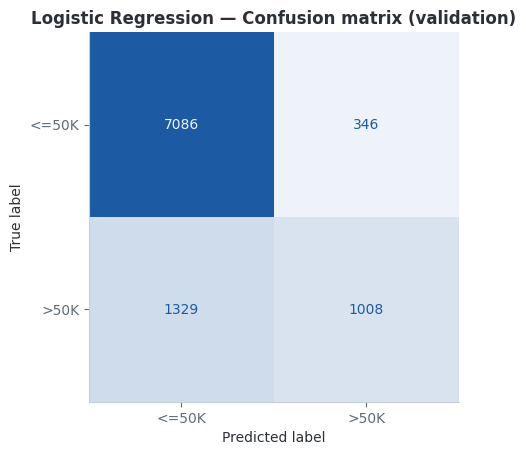

In [35]:
y_val_pred = baseline_pipe.predict(X_val)
y_val_proba = baseline_pipe.predict_proba(X_val)[:, 1]

cm = confusion_matrix(y_val, y_val_pred)
tn, fp, fn, tp = cm.ravel()
print(f"True negatives : {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives : {tp}")

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"]).plot(cmap=BLUES, colorbar=False)
plt.title("Logistic Regression — Confusion matrix (validation)")
plt.show()

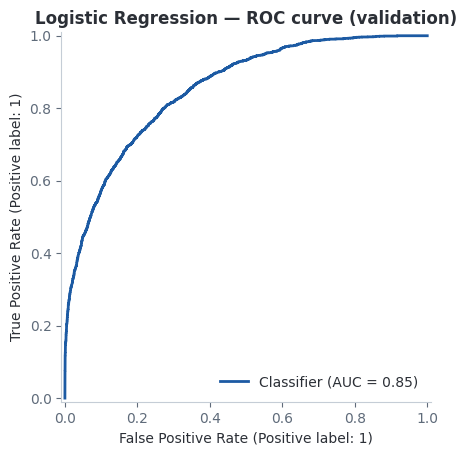

In [36]:
RocCurveDisplay.from_predictions(y_val, y_val_proba)
plt.title("Logistic Regression — ROC curve (validation)")
plt.show()

**The model misses a large share of the people who actually earn >50K. Why, and what can we do?**

With the default threshold of 0.5 and only ~24% positives, the model is cautious about predicting ">50K": recall on the positive class is only around **43%**: more than half of the real high earners become false negatives. This is the class-imbalance problem. Possible remedies, compared in Part 2:
- **class weights** (`class_weight="balanced"`) so mistakes on the rare class cost more during training;
- **resampling** (e.g. oversampling the minority class) applied inside the pipeline on training data only;
- **moving the decision threshold** below 0.5, chosen on the validation set.

### Takeaways of Part 1

- About **24%** of people earn >50K: the classes are imbalanced, so accuracy is misleading.
- The **raw pay gap** by sex and race remains **between people with the same education or occupation**.
- The reference model uses **job-related columns only**; protected attributes and their proxies are dropped **inside the pipeline**.
- The Logistic Regression baseline ranks people reasonably well (ROC-AUC ≈ 0.85) but finds fewer than half of the high earners.

# Part 2 — Experiment Tracking, Class Imbalance and Three Models

In this part we start logging every model in **MLflow**, choose how to deal with **class imbalance**, and compare **three models**. All models use fixed, reasonable settings; tuning comes in Part 3.

## Experiment tracking with MLflow

We will train many models. **MLflow** records, for each training **run**, its settings (parameters), its scores (metrics) and files such as plots or the trained model (artifacts). Runs are grouped in one **experiment**, `adult-pay-equity`, and each run gets a `stage` tag (`imbalance`, `models`, `tuning`…) so we can filter them later.

MLflow stores everything in a small database plus a folder of files. On Colab these files disappear when the session ends, so we work in `/content/mlflow` and **copy everything to Google Drive** at the end of Parts 3 and 4.

In [37]:
try:
    import google.colab  # only exists when running on Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DRIVE_BACKUP_DIR = None  # stays None if Drive is not available

if IN_COLAB:
    MLFLOW_DIR = "/content/mlflow"
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_BACKUP_DIR = "/content/drive/MyDrive/Supervised Learning & Model Engineering/Final Project/Code adapted to problematic/mlflow"
        if os.path.exists(DRIVE_BACKUP_DIR):            # restore previous runs
            shutil.copytree(DRIVE_BACKUP_DIR, MLFLOW_DIR, dirs_exist_ok=True)
    except Exception as error:
        # If Drive cannot be mounted, MLflow still works locally for this session
        print("Could not mount Google Drive:", error)
        print("MLflow will work, but download the runs at the end (Part V).")
else:
    MLFLOW_DIR = os.path.abspath("mlflow")

os.makedirs(MLFLOW_DIR, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DIR}/mlflow.db")

EXPERIMENT_NAME = "adult-pay-equity"
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"{MLFLOW_DIR}/artifacts")
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow data stored in:", MLFLOW_DIR)

Mounted at /content/drive
MLflow data stored in: /content/mlflow


### Evaluation and logging helpers

`classification_metrics` computes the same metrics as before, as a dictionary so MLflow can log it. `train_and_log` trains a pipeline, scores it on the **validation set**, and logs its settings, scores and confusion matrix in MLflow (optionally the trained pipeline too).

In [38]:
def classification_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }


def simple_params(estimator, prefix):
    # Keep only simple values (numbers, text, booleans, None) so MLflow can store them
    return {
        f"{prefix}__{key}": value
        for key, value in estimator.get_params(deep=False).items()
        if isinstance(value, (int, float, str, bool, type(None)))
    }


def train_and_log(run_name, pipe, stage, remedy, log_model=False):
    # 1) Train
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    # 2) Evaluate on validation (+ train ranking metrics to check overfitting)
    val_proba = pipe.predict_proba(X_val)[:, 1]
    val_pred = (val_proba >= 0.5).astype(int)
    val_metrics = classification_metrics(y_val, val_pred, val_proba)

    train_proba = pipe.predict_proba(X_train)[:, 1]
    extra_metrics = {
        "train_roc_auc": roc_auc_score(y_train, train_proba),
        "train_pr_auc": average_precision_score(y_train, train_proba),
        "training_time_seconds": training_time,
    }

    # 3) Log to MLflow
    model = pipe.named_steps["model"]
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"stage": stage, "model_type": type(model).__name__, "remedy": remedy})
        mlflow.log_params(simple_params(model, "model"))
        if "sampler" in pipe.named_steps:
            mlflow.log_params(simple_params(pipe.named_steps["sampler"], "sampler"))
        mlflow.log_metrics({f"val_{name}": value for name, value in val_metrics.items()})
        mlflow.log_metrics(extra_metrics)

        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay.from_predictions(
            y_val, val_pred, display_labels=["<=50K", ">50K"], ax=ax, colorbar=False, cmap=BLUES,
        )
        ax.set_title(run_name)
        mlflow.log_figure(fig, "confusion_matrix_val.png")
        plt.close(fig)

        # 4) Optionally save the whole fitted pipeline
        if log_model:
            # "cloudpickle" can save our custom AdultFeatureEngineer class.
            # Only reload model files you created yourself (pickle files can run code).
            mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")

    return pd.Series({**val_metrics, **extra_metrics}, name=run_name)

## Class imbalance

Only **~24%** of people earn >50K. With the default 0.5 threshold, the baseline predicts ">50K" only when it is very sure, so it misses many high earners.

| Metric | Question it answers | Depends on the threshold? |
|---|---|---|
| **Recall** | Of the real high earners, how many do we find? | yes |
| **Precision** | Of the people we flag, how many really earn >50K? | yes |
| **F1** | A balance of precision and recall | yes |
| **ROC-AUC** | How well does the model rank high earners above the others? | no |
| **AP** (`pr_auc` in our tables) | Ranking quality focused on the rare class; random baseline = prevalence (≈ 0.24) | no |

For the regulator, the probabilities give each group's **expected** rate, and the yes/no predictions flag individuals. AP is our main selection metric; we also report precision and recall.

We compare four options on Logistic Regression, changing only the remedy:

| Remedy | Idea |
|---|---|
| none | the Part 1 baseline |
| class weights | errors on the rare class count more during training (`class_weight="balanced"`) |
| undersampling | randomly drop majority rows until the classes are balanced |
| SMOTE | create synthetic minority rows between real neighbours |

Resampling must only touch the **training** data. The `imblearn` pipeline applies the sampler during `fit` only; validation keeps its real 24% rate.

In [39]:
def build_pipeline_with_sampler(model, sampler):
    # Same steps as build_pipeline, plus a resampling step applied during fit only
    steps = [("features", AdultFeatureEngineer()), ("preprocess", build_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps)

In [40]:
remedies = {
    "none": dict(
        model=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        sampler=None,
    ),
    "class_weight": dict(
        model=LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        sampler=None,
    ),
    "undersampling": dict(
        model=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        sampler=RandomUnderSampler(random_state=RANDOM_STATE),
    ),
    "smote": dict(
        model=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        sampler=SMOTE(random_state=RANDOM_STATE),
    ),
}

remedy_results = []
for remedy_name, parts in remedies.items():
    pipe = build_pipeline_with_sampler(parts["model"], parts["sampler"])
    result = train_and_log(
        run_name=f"logreg__{remedy_name}",
        pipe=pipe,
        stage="imbalance",
        remedy=remedy_name,
    )
    remedy_results.append(result.rename(remedy_name))

remedy_comparison = pd.DataFrame(remedy_results)
remedy_comparison[["precision", "recall", "f1", "roc_auc", "pr_auc", "accuracy", "training_time_seconds"]].round(3)

,precision,recall,f1,roc_auc,pr_auc,accuracy,training_time_seconds
none,0.744,0.431,0.546,0.853,0.692,0.829,0.506
class_weight,0.508,0.756,0.607,0.854,0.691,0.766,0.502
undersampling,0.510,0.760,0.611,0.854,0.689,0.768,0.200
smote,0.510,0.757,0.609,0.854,0.692,0.768,0.977


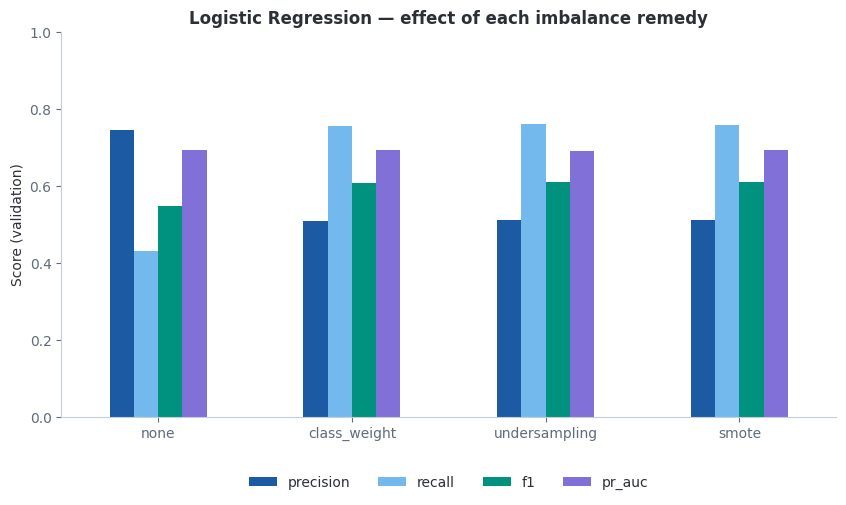

In [41]:
# 4 metrics = 4 series colours; ROC-AUC stays in the table above
remedy_comparison[["precision", "recall", "f1", "pr_auc"]].plot(kind="bar", figsize=(10, 5))
plt.ylabel("Score (validation)")
plt.ylim(0, 1)
plt.title("Logistic Regression — effect of each imbalance remedy")
plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)  # below the chart
plt.show()

**What happens to precision and recall?**
All three remedies give the same trade-off: **recall rises from about 0.43 to 0.76**, **precision falls from about 0.74 to 0.51**, and F1 improves (≈ 0.55 → 0.61).

**Why do ROC-AUC and AP barely change?**
They measure the **ranking** of people, which the remedies hardly change: the remedies mostly push all probabilities up, which is close to **lowering the threshold**. They move the operating point; they do not make the model smarter.

**Which remedy do we keep?**
**Class weights**: same result, all real data is used (undersampling throws away two thirds of the majority rows), no synthetic people (SMOTE creates unrealistic "half-married" profiles from one-hot columns), no extra step, and the same parameter exists in all three models.

**A deliberate simplification.** The course treats the class weight as a hyperparameter to validate. We keep it fixed at `"balanced"`: it did not change the ranking here, and we control the precision/recall trade-off later with the **threshold**. Class weights can also distort probabilities; Part 4 checks and corrects this.

## Three models

All three use class weights and the **same pipeline**, and are scored on the **same validation set**:

| Model | Idea |
|---|---|
| Logistic Regression | one linear score: simple, fast, interpretable |
| Random Forest | many deep trees on random samples, averaged: captures non-linear effects and interactions |
| LightGBM | trees built one after another, each correcting the previous ones (gradient boosting): usually the strongest on tabular data |

Each fitted pipeline is also saved in MLflow. MLflow warns that saving with cloudpickle can run code when loading: this is expected, and we only reload files we created ourselves.

In [42]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        verbosity=-1,
    ),
}

fitted_pipes = {}
model_results = []
for name, model in models.items():
    pipe = build_pipeline(model)
    result = train_and_log(
        run_name=name,
        pipe=pipe,
        stage="models",
        remedy="class_weight",
        log_model=True,
    )
    fitted_pipes[name] = pipe
    model_results.append(result)
    print(f"{name:20s} done in {result['training_time_seconds']:.1f}s")

2026/10/18 18:25:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression  done in 0.5s


2026/10/18 18:25:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest        done in 4.6s


2026/10/18 18:25:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LightGBM             done in 0.9s


In [43]:
comparison = pd.DataFrame(model_results).sort_values("pr_auc", ascending=False)

comparison[[
    "precision", "recall", "f1", "roc_auc", "pr_auc", "accuracy", "training_time_seconds",
]].round(3)

,precision,recall,f1,roc_auc,pr_auc,accuracy,training_time_seconds
LightGBM,0.544,0.804,0.649,0.890,0.772,0.792,0.868
Random Forest,0.556,0.749,0.638,0.879,0.750,0.797,4.609
Logistic Regression,0.508,0.756,0.607,0.854,0.691,0.766,0.545


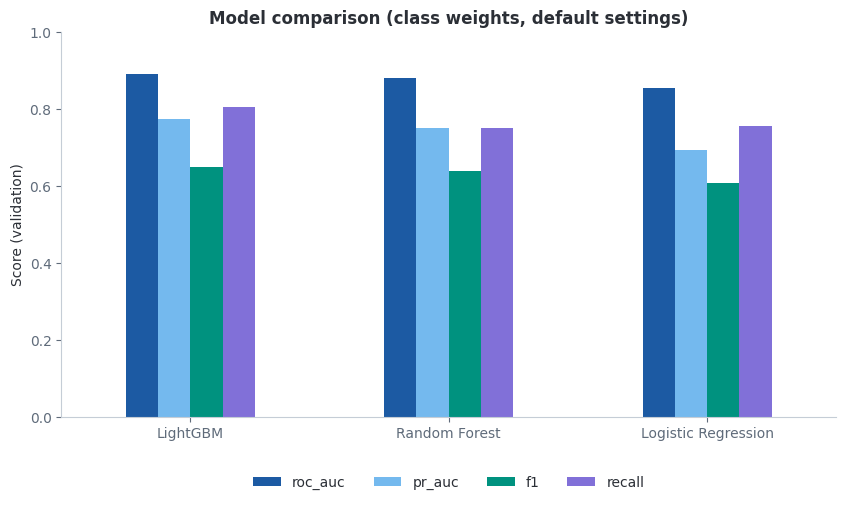

In [44]:
comparison[["roc_auc", "pr_auc", "f1", "recall"]].plot(kind="bar", figsize=(10, 5))
plt.ylabel("Score (validation)")
plt.ylim(0, 1)
plt.title("Model comparison (class weights, default settings)")
plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)  # below the chart
plt.show()

### Precision–recall curves

Each curve shows every possible threshold at once; higher and further right is better. The dashed line is a random model (precision = prevalence).

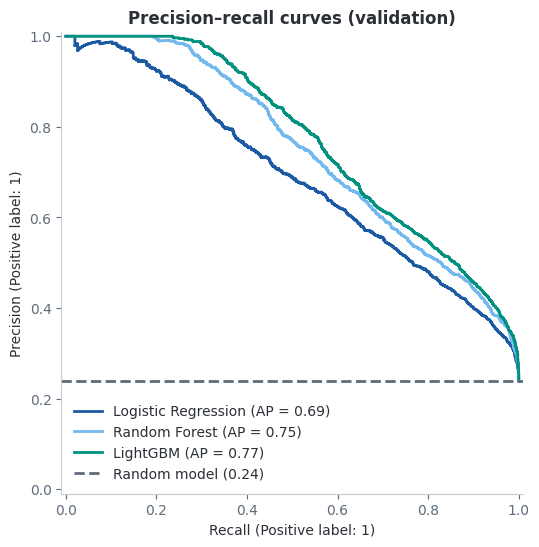

In [45]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted_pipes.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_val, y_val, name=name, ax=ax)

ax.axhline(y_val.mean(), linestyle="--", color=STEEL, label=f"Random model ({y_val.mean():.2f})")
ax.set_title("Precision–recall curves (validation)")
ax.legend(loc="lower left")
plt.show()

### Confusion matrices

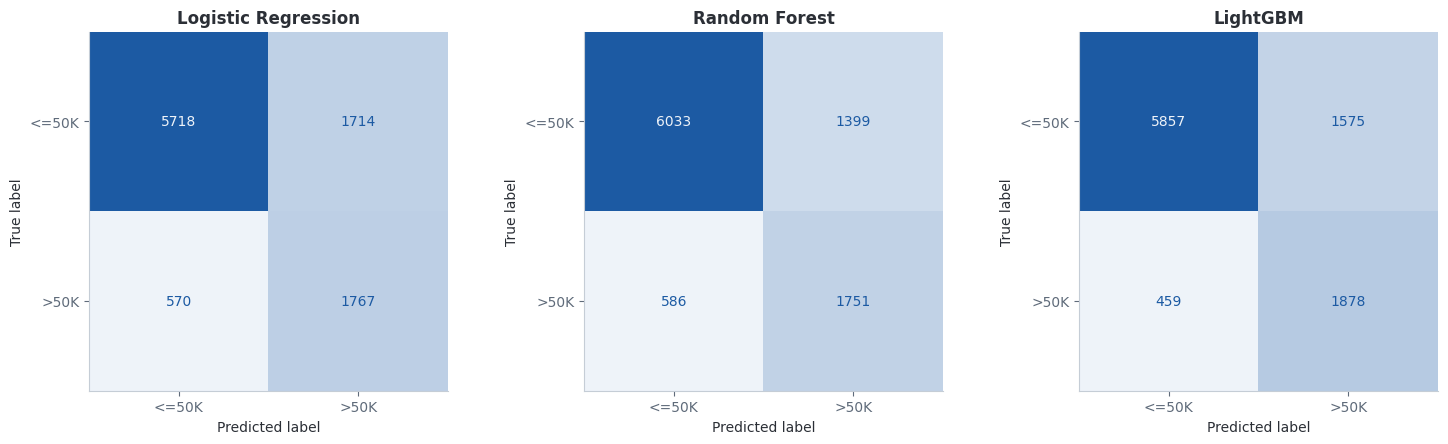

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pipe) in zip(axes, fitted_pipes.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_val, y_val, display_labels=["<=50K", ">50K"], ax=ax, colorbar=False, cmap=BLUES,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Overfitting check: train vs validation

In [47]:
overfit = comparison[["train_roc_auc", "roc_auc", "train_pr_auc", "pr_auc"]].rename(
    columns={"roc_auc": "val_roc_auc", "pr_auc": "val_pr_auc"}
)
overfit["roc_auc_gap"] = overfit["train_roc_auc"] - overfit["val_roc_auc"]
overfit.round(3)

,train_roc_auc,val_roc_auc,train_pr_auc,val_pr_auc,roc_auc_gap
LightGBM,0.911,0.890,0.802,0.772,0.021
Random Forest,0.916,0.879,0.807,0.750,0.037
Logistic Regression,0.853,0.854,0.686,0.691,-0.000


**What did each step bring?**
- **Logistic Regression → Random Forest:** the largest gain (AP ≈ 0.69 → 0.75, ROC-AUC ≈ 0.85 → 0.88). Trees capture interactions, e.g. the effect of education depends on occupation and age.
- **Random Forest → LightGBM:** a further gain, with the best ROC-AUC (≈ 0.89), AP (≈ 0.77) and F1, and the highest recall (≈ 0.80) at similar precision. It is also fast (about 1 s to train, versus 5 s for the forest).

**Is any model overfitting?**
Only mildly, and only the trees: the Random Forest scores about 0.04 ROC-AUC higher on train than on validation, LightGBM about 0.02. Logistic Regression has no gap. Tuning in Part 3 targets these complexity settings.

**Which model do we carry forward?**
**LightGBM** leads on every ranking metric, but with default settings: all three models are tuned in Part 3 before the final choice. Precision, recall and F1 above use the 0.5 threshold; the final threshold is chosen in Part 4.

### The runs in MLflow

`mlflow.search_runs` lists every run as a table. Each model run also stores the fitted pipeline, which can be reloaded without retraining (the class-weighted Logistic Regression appears twice: once per stage).

In [48]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])

columns = [
    "tags.mlflow.runName", "tags.stage", "tags.remedy",
    "metrics.val_precision", "metrics.val_recall", "metrics.val_f1",
    "metrics.val_roc_auc", "metrics.val_pr_auc", "metrics.training_time_seconds",
]
runs[columns].sort_values("metrics.val_pr_auc", ascending=False).round(3)

,tags.mlflow.runName,tags.stage,tags.remedy,metrics.val_precision,metrics.val_recall,metrics.val_f1,metrics.val_roc_auc,metrics.val_pr_auc,metrics.training_time_seconds
9,LightGBM (tuned),tuned,class_weight,0.544,0.804,0.649,0.893,0.776,1.905
0,LightGBM,models,class_weight,0.544,0.804,0.649,0.890,0.772,0.868
8,LightGBM (default),default,class_weight,0.544,0.804,0.649,0.890,0.772,0.846
122,LightGBM,models,class_weight,0.544,0.804,0.649,0.890,0.772,0.968
11,Random Forest (tuned),tuned,class_weight,0.529,0.780,0.630,0.879,0.752,10.727
...,...,...,...,...,...,...,...,...,...
117,Logistic Regression — trial 3,tuning_trial,None,NaN,NaN,NaN,NaN,NaN,NaN
118,Logistic Regression — trial 2,tuning_trial,None,NaN,NaN,NaN,NaN,NaN,NaN
119,Logistic Regression — trial 1,tuning_trial,None,NaN,NaN,NaN,NaN,NaN,NaN
120,Logistic Regression — trial 0,tuning_trial,None,NaN,NaN,NaN,NaN,NaN,NaN


In [49]:
lgbm_run_id = runs.loc[runs["tags.mlflow.runName"] == "LightGBM", "run_id"].iloc[0]
reloaded = mlflow.sklearn.load_model(f"runs:/{lgbm_run_id}/model")

print("Reloaded pipeline ROC-AUC on validation:",
      round(roc_auc_score(y_val, reloaded.predict_proba(X_val)[:, 1]), 3))

Reloaded pipeline ROC-AUC on validation: 0.89


# Part 3 — Hyperparameter Tuning with Cross-Validation

We tune the three models with **Optuna**, score every setting with **cross-validation on the training set**, log every trial in MLflow, and choose the final model on the validation set.

## Why cross-validation for tuning

Tuning tries many settings and keeps the best. If we scored them on the validation set, we would pick the setting that happens to do best **on those 9,769 people**, and its score would be optimistic. So each setting is scored with **5-fold cross-validation on the training set only**:

```
training set:  [ fold 1 | fold 2 | fold 3 | fold 4 | fold 5 ]
round 1:         validation  train   train   train   train
round 2:         train   validation  train   train   train
...              (5 rounds: each fold is used for scoring once)
CV score = mean of the 5 fold scores
```

- The whole pipeline is refitted in each round on 4 folds, so nothing leaks from the scored fold.
- `StratifiedKFold` keeps the share of >50K in every fold, like `stratify=y` in our split.
- The validation set is not used during tuning, and the test set stays locked until Part 4.
- We tune for **AP** (`scoring="average_precision"`): ranking quality focused on the high earners.

First, the cross-validated scores of the Part 2 models:

In [50]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_pr_auc(pipe):
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    return scores.mean(), scores.std(), scores

In [51]:
default_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1,
    ),
}

rows = []
for name, model in default_models.items():
    mean, std, scores = cv_pr_auc(build_pipeline(model))
    rows.append({"model": name, "cv_pr_auc_mean": mean, "cv_pr_auc_std": std})
    print(f"{name:20s} fold scores: {np.round(scores, 3)}")

default_cv = pd.DataFrame(rows).set_index("model")
default_cv.round(4)

Logistic Regression  fold scores: [0.688 0.684 0.686 0.674 0.688]
Random Forest        fold scores: [0.738 0.747 0.737 0.719 0.747]
LightGBM             fold scores: [0.759 0.771 0.76  0.747 0.767]


,cv_pr_auc_mean,cv_pr_auc_std
model,,
Logistic Regression,0.6840,0.0051
Random Forest,0.7376,0.0101
LightGBM,0.7608,0.0084


The five fold scores differ a little because each fold contains different people. Their **standard deviation** shows how much a score moves by chance: a difference much smaller than it is not a convincing improvement.

## Optuna

Optuna searches for good hyperparameters automatically: it looks at the scores of previous trials and tries more values near the ones that worked (TPE algorithm; `seed=42` makes it reproducible). `log=True` tries values on a logarithmic scale, suited to parameters like a learning rate.

Each function below turns a trial into a model. `class_weight="balanced"` stays fixed; we tune the parameters that control **model complexity** (regularisation for Logistic Regression; depth, leaf size and number of trees for the forest; learning rate, leaves and regularisation for LightGBM).

In [52]:
def make_logistic_regression(trial):
    return LogisticRegression(
        C=trial.suggest_float("C", 1e-3, 100, log=True),
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )


def make_random_forest(trial):
    return RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
        max_depth=trial.suggest_int("max_depth", 5, 30),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        max_features=trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


def make_lightgbm(trial):
    return LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 100, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        subsample_freq=1,  # needed for subsample to have an effect
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        class_weight="balanced",
        random_state=RANDOM_STATE,
        verbosity=-1,
    )


MODEL_BUILDERS = {
    "Logistic Regression": make_logistic_regression,
    "Random Forest": make_random_forest,
    "LightGBM": make_lightgbm,
}

# Number of trials per model. Random Forest is the slowest, so it gets fewer.
N_TRIALS = {
    "Logistic Regression": 15,
    "Random Forest": 15,
    "LightGBM": 30,
}

## Running the tuning

For each model, one **parent run** in MLflow contains one **child run per trial**, with the trial's parameters, its CV mean and standard deviation, its run time and the five fold scores.

> This cell takes **about 15–20 minutes**. Do not interrupt it; to see progress, open the output area (the trial lines may be collapsed).

In [53]:
def make_objective(model_name):
    builder = MODEL_BUILDERS[model_name]

    def objective(trial):
        pipe = build_pipeline(builder(trial))

        start = time.perf_counter()
        mean, std, scores = cv_pr_auc(pipe)
        duration = time.perf_counter() - start

        with mlflow.start_run(run_name=f"{model_name} — trial {trial.number}", nested=True):
            mlflow.set_tags({"stage": "tuning_trial", "model_type": model_name})
            mlflow.log_params(trial.params)
            mlflow.log_metrics({
                "cv_pr_auc_mean": mean,
                "cv_pr_auc_std": std,
                "cv_time_seconds": duration,
            })
            mlflow.log_dict({"fold_pr_auc": scores.tolist()}, "cv_fold_scores.json")

        print(f"  trial {trial.number:2d} | CV PR-AUC = {mean:.4f} ± {std:.4f} | {duration:5.1f}s")
        return mean

    return objective

In [54]:
studies = {}

for model_name in MODEL_BUILDERS:
    print(f"\n=== Tuning {model_name} ({N_TRIALS[model_name]} trials) ===")
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        study_name=model_name,
    )

    with mlflow.start_run(run_name=f"tuning — {model_name}"):
        mlflow.set_tags({"stage": "tuning", "model_type": model_name})
        study.optimize(make_objective(model_name), n_trials=N_TRIALS[model_name])

        mlflow.log_params({f"best__{k}": v for k, v in study.best_params.items()})
        mlflow.log_metric("best_cv_pr_auc", study.best_value)

        ax = optuna.visualization.matplotlib.plot_optimization_history(study)
        ax.set_title(f"Optimization history — {model_name}", loc="left")
        mlflow.log_figure(ax.figure, "optimization_history.png")
        plt.close(ax.figure)

    studies[model_name] = study
    print(f"Best CV PR-AUC for {model_name}: {study.best_value:.4f}")
    print("Best parameters:", study.best_params)


=== Tuning Logistic Regression (15 trials) ===
  trial  0 | CV PR-AUC = 0.6809 ± 0.0050 |   2.0s
  trial  1 | CV PR-AUC = 0.6844 ± 0.0051 |   2.6s
  trial  2 | CV PR-AUC = 0.6843 ± 0.0051 |   2.7s
  trial  3 | CV PR-AUC = 0.6840 ± 0.0051 |   2.4s
  trial  4 | CV PR-AUC = 0.6647 ± 0.0049 |   1.4s
  trial  5 | CV PR-AUC = 0.6647 ± 0.0049 |   1.4s
  trial  6 | CV PR-AUC = 0.6522 ± 0.0056 |   1.2s
  trial  7 | CV PR-AUC = 0.6843 ± 0.0051 |   2.3s
  trial  8 | CV PR-AUC = 0.6840 ± 0.0051 |   2.3s
  trial  9 | CV PR-AUC = 0.6842 ± 0.0051 |   2.3s
  trial 10 | CV PR-AUC = 0.6844 ± 0.0051 |   2.4s
  trial 11 | CV PR-AUC = 0.6844 ± 0.0051 |   2.5s
  trial 12 | CV PR-AUC = 0.6844 ± 0.0051 |   2.4s
  trial 13 | CV PR-AUC = 0.6843 ± 0.0051 |   2.4s
  trial 14 | CV PR-AUC = 0.6844 ± 0.0051 |   2.5s
Best CV PR-AUC for Logistic Regression: 0.6844
Best parameters: {'C': 71.06361724509843}

=== Tuning Random Forest (15 trials) ===
  trial  0 | CV PR-AUC = 0.7324 ± 0.0098 |  11.1s
  trial  1 | CV PR-AU

### The search, trial by trial

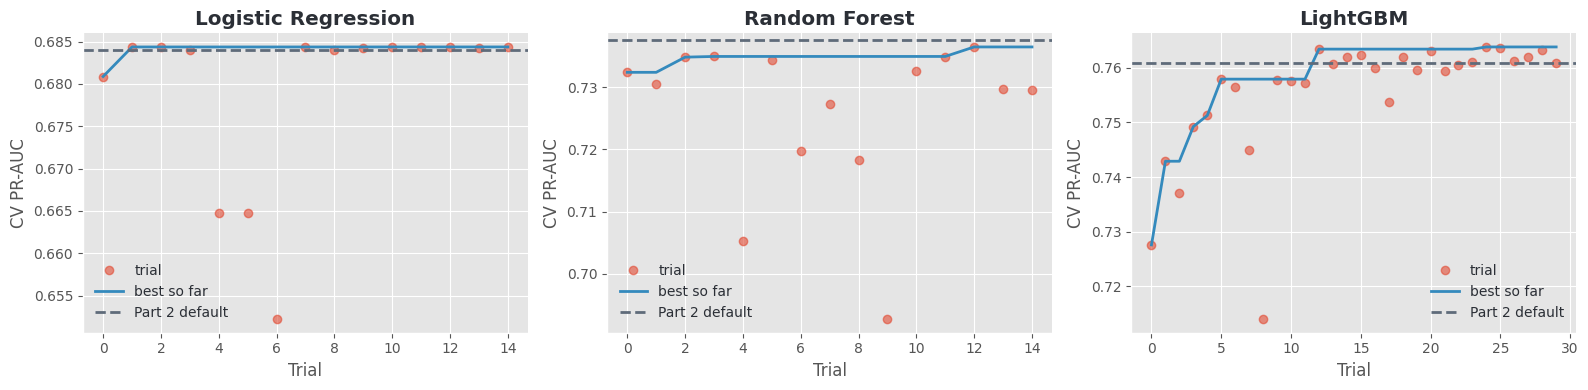

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, study) in zip(axes, studies.items()):
    trials = study.trials_dataframe()
    ax.plot(trials["number"], trials["value"], "o", alpha=0.6, label="trial")
    ax.plot(trials["number"], trials["value"].cummax(), label="best so far")
    ax.axhline(default_cv.loc[name, "cv_pr_auc_mean"], linestyle="--", color=STEEL,
               label="Part 2 default")
    ax.set_title(name)
    ax.set_xlabel("Trial")
    ax.set_ylabel("CV PR-AUC")
    ax.legend()

plt.tight_layout()
plt.show()

### Which hyperparameters mattered?

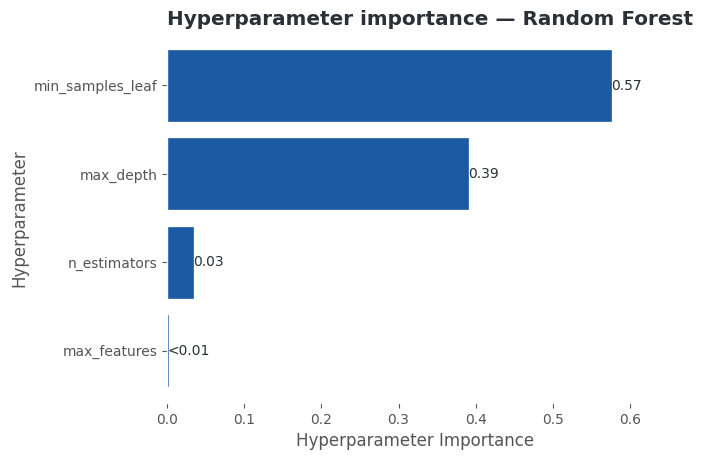

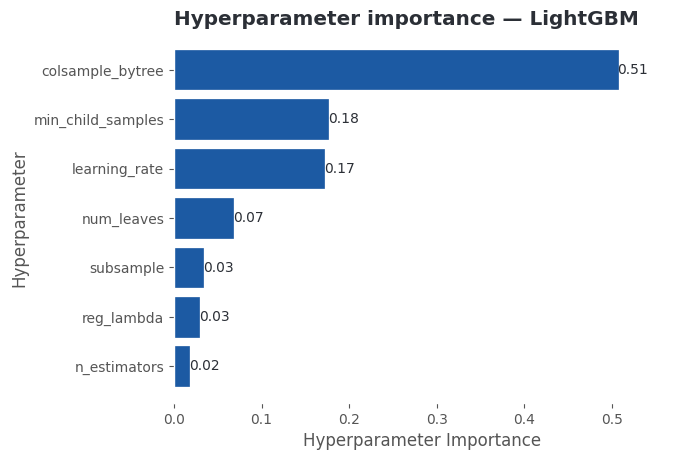

In [56]:
for name in ["Random Forest", "LightGBM"]:
    ax = optuna.visualization.matplotlib.plot_param_importances(studies[name])
    ax.set_title(f"Hyperparameter importance — {name}", loc="left")  # replaces Optuna's own title
    ax.set_facecolor("white")                 # Optuna draws in its own grey style: apply ours
    ax.grid(False)
    for bar in ax.patches:
        bar.set_color(NAVY)
    if ax.get_legend() is not None:           # Optuna's legend adds nothing here
        ax.get_legend().remove()
    plt.show()

In [57]:
# All LightGBM trials, best first
studies["LightGBM"].trials_dataframe().sort_values("value", ascending=False).head(10).round(4)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample,system_attrs_tpe:relative_params:0,state
24,24,0.7638,2026-10-18 18:35:49.412665,2026-10-18 18:35:58.498908,0 days 00:00:09.086243,0.5081,0.0230,5,600,22,0.0490,0.8897,"{""colsample_bytree"": 0.508074163409606, ""learn...",COMPLETE
25,25,0.7636,2026-10-18 18:35:58.498969,2026-10-18 18:36:10.725119,0 days 00:00:12.226150,0.5253,0.0243,5,750,36,0.1532,0.9903,"{""colsample_bytree"": 0.5252960010675186, ""lear...",COMPLETE
12,12,0.7634,2026-10-18 18:34:04.201945,2026-10-18 18:34:13.625242,0 days 00:00:09.423297,0.5136,0.0224,6,600,23,0.2498,0.9154,"{""colsample_bytree"": 0.5136181800925835, ""lear...",COMPLETE
28,28,0.7632,2026-10-18 18:36:31.307021,2026-10-18 18:36:40.044939,0 days 00:00:08.737918,0.5040,0.0365,5,550,28,0.4064,0.8571,"{""colsample_bytree"": 0.5040130183772001, ""lear...",COMPLETE
20,20,0.7630,2026-10-18 18:35:09.841373,2026-10-18 18:35:20.474581,0 days 00:00:10.633208,0.5998,0.0263,5,600,39,0.0839,0.8815,"{""colsample_bytree"": 0.5998288383760904, ""lear...",COMPLETE
15,15,0.7623,2026-10-18 18:34:28.559367,2026-10-18 18:34:35.837499,0 days 00:00:07.278132,0.6800,0.0419,20,650,10,0.0316,0.8746,"{""colsample_bytree"": 0.6800219364352234, ""lear...",COMPLETE
18,18,0.7620,2026-10-18 18:34:51.711213,2026-10-18 18:35:01.590080,0 days 00:00:09.878867,0.7106,0.0361,33,750,20,0.4723,0.9095,"{""colsample_bytree"": 0.7106052103640661, ""lear...",COMPLETE
27,27,0.7620,2026-10-18 18:36:18.304862,2026-10-18 18:36:31.306929,0 days 00:00:13.002067,0.5114,0.0124,9,750,28,0.3081,0.9333,"{""colsample_bytree"": 0.511364762540471, ""learn...",COMPLETE
14,14,0.7620,2026-10-18 18:34:21.930753,2026-10-18 18:34:28.559314,0 days 00:00:06.628561,0.6323,0.0360,10,550,11,0.0116,0.9155,"{""colsample_bytree"": 0.6323129542304836, ""lear...",COMPLETE
26,26,0.7611,2026-10-18 18:36:10.725216,2026-10-18 18:36:18.304805,0 days 00:00:07.579589,0.5267,0.0252,6,550,13,0.0309,0.8482,"{""colsample_bytree"": 0.5266978707863448, ""lear...",COMPLETE


- **Logistic Regression:** the score is flat for almost every `C`; only very strong regularisation hurts.
- **Random Forest:** `min_samples_leaf` and `max_depth` matter most: the parameters that control tree complexity. Very shallow trees underfit. Best trial: 400 trees, depth 14, `min_samples_leaf` = 6.
- **LightGBM:** `colsample_bytree`, `min_child_samples` and `learning_rate` lead. The best trials use many small steps (≈ 600 trees, learning rate ≈ 0.02) and moderate trees (≈ 22 leaves).

These rankings change from run to run (most trials differ by less than 0.01), so they are **indicative only**.

## Tuned vs default models on the validation set

Each model is rebuilt with its best parameters, fitted on the whole training set, and scored **once** on validation. The tuned pipelines are saved in MLflow.

In [58]:
def fit_and_evaluate(name, pipe, stage, params=None, log_model=False):
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    val_proba = pipe.predict_proba(X_val)[:, 1]
    val_pred = (val_proba >= 0.5).astype(int)
    val_metrics = classification_metrics(y_val, val_pred, val_proba)

    train_proba = pipe.predict_proba(X_train)[:, 1]
    extra_metrics = {
        "train_pr_auc": average_precision_score(y_train, train_proba),
        "training_time_seconds": training_time,
    }

    with mlflow.start_run(run_name=f"{name} ({stage})") as run:
        mlflow.set_tags({"stage": stage, "model_type": name, "remedy": "class_weight"})
        if params:
            mlflow.log_params(params)
        mlflow.log_metrics({f"val_{metric}": value for metric, value in val_metrics.items()})
        mlflow.log_metrics(extra_metrics)
        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay.from_predictions(
            y_val, val_pred, display_labels=["<=50K", ">50K"], ax=ax, colorbar=False, cmap=BLUES,
        )
        ax.set_title(f"{name} ({stage})")
        mlflow.log_figure(fig, "confusion_matrix_val.png")
        plt.close(fig)
        if log_model:
            # cloudpickle can save our custom AdultFeatureEngineer class (see Part 2)
            mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")

    return {**val_metrics, **extra_metrics, "run_id": run.info.run_id}

In [59]:
rows = []
tuned_pipes = {}   # kept in memory for Part 4
for name, study in studies.items():
    best_model = MODEL_BUILDERS[name](optuna.trial.FixedTrial(study.best_params))
    tuned_pipe = build_pipeline(best_model)
    tuned = fit_and_evaluate(name, tuned_pipe, stage="tuned", params=study.best_params, log_model=True)
    tuned_pipes[name] = tuned_pipe
    default = fit_and_evaluate(name, build_pipeline(default_models[name]), stage="default")

    for version, metrics in [("default", default), ("tuned", tuned)]:
        rows.append({"model": name, "version": version, **metrics})

results = pd.DataFrame(rows).set_index(["model", "version"])
results[["precision", "recall", "f1", "roc_auc", "pr_auc", "train_pr_auc", "training_time_seconds"]].round(3)

2026/10/18 18:36:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/18 18:37:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/18 18:37:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

precision  recall     f1  roc_auc  pr_auc  \
model               version                                              
Logistic Regression default      0.508   0.756  0.607    0.854   0.691   
                    tuned        0.508   0.756  0.607    0.854   0.692   
Random Forest       default      0.556   0.749  0.638    0.879   0.750   
                    tuned        0.529   0.780  0.630    0.879   0.752   
LightGBM            default      0.544   0.804  0.649    0.890   0.772   
                    tuned        0.544   0.804  0.649    0.893   0.776   

                             train_pr_auc  training_time_seconds  
model               version                                       
Logistic Regression default         0.686                  0.544  
                    tuned           0.686                  0.529  
Random Forest       default         0.807                  4.570  
                    tuned           0.783                 10.678  
LightGBM            default         0.802                  0.845  
                    tuned           0.788                  1.970

In [60]:
summary = pd.DataFrame({
    "default_cv_pr_auc": default_cv["cv_pr_auc_mean"],
    "tuned_cv_pr_auc": pd.Series({name: s.best_value for name, s in studies.items()}),
    "default_val_pr_auc": results.xs("default", level="version")["pr_auc"],
    "tuned_val_pr_auc": results.xs("tuned", level="version")["pr_auc"],
})
summary["gain_on_val"] = summary["tuned_val_pr_auc"] - summary["default_val_pr_auc"]
summary.round(4)

,default_cv_pr_auc,tuned_cv_pr_auc,default_val_pr_auc,tuned_val_pr_auc,gain_on_val
Logistic Regression,0.6840,0.6844,0.6914,0.6917,0.0003
Random Forest,0.7376,0.7365,0.7504,0.7516,0.0011
LightGBM,0.7608,0.7638,0.7717,0.7763,0.0045


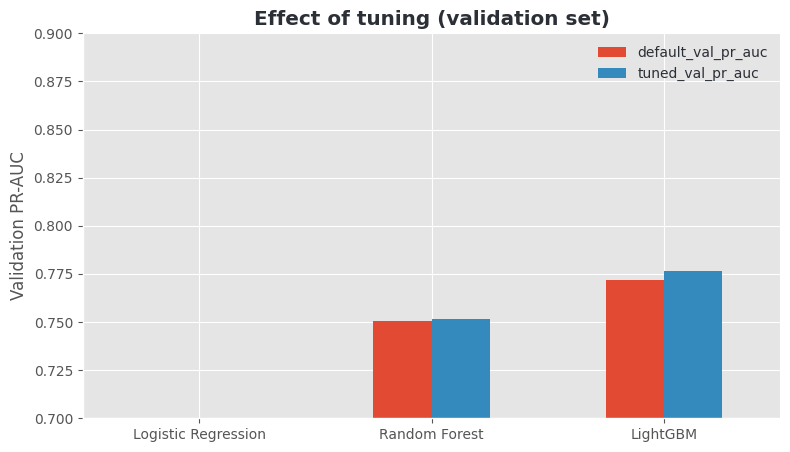

In [61]:
summary[["default_val_pr_auc", "tuned_val_pr_auc"]].plot(kind="bar", figsize=(9, 5))
plt.ylabel("Validation PR-AUC")
plt.ylim(0.7, 0.9)
plt.title("Effect of tuning (validation set)")
plt.xticks(rotation=0)
plt.show()

**How much did tuning help?**
A little: on validation, AP rises by about **+0.005** for LightGBM, **+0.001** for the Random Forest and ~0 for Logistic Regression, less than the CV standard deviation. For the Random Forest the best tuned CV score is even slightly below the default (its default unlimited depth was outside our search range). The ranking of the models does not change: **the model family mattered more than the hyperparameters.**

**Is the best CV score honest?**
Slightly optimistic in principle, since we kept the best of many trials. Here the effect is too small to see: validation scores are about 0.01 *higher* than CV scores for every model, including the defaults (random variation between samples). The tuned and default models rank the same way in CV and on validation, so tuning did not overfit the folds.

**Did tuning reduce overfitting?**
Yes for both tree models: train AP drops (LightGBM 0.80 → 0.79, Random Forest 0.81 → 0.78) while validation AP rises slightly.

## Final choice

In [62]:
tuned_results = results.xs("tuned", level="version")
FINAL_MODEL_NAME = tuned_results["pr_auc"].idxmax()
final_pipe = tuned_pipes[FINAL_MODEL_NAME]    # the tuned pipeline, already fitted on the training set
final_run_id = tuned_results.loc[FINAL_MODEL_NAME, "run_id"]

print("Final model:", FINAL_MODEL_NAME)
print("Validation PR-AUC:", round(tuned_results.loc[FINAL_MODEL_NAME, "pr_auc"], 4))
print("Best parameters:", studies[FINAL_MODEL_NAME].best_params)

# Mark the chosen run in MLflow so Part 4 can find it
with mlflow.start_run(run_id=final_run_id):
    mlflow.set_tag("final_model", "true")

Final model: LightGBM
Validation PR-AUC: 0.7763
Best parameters: {'n_estimators': 600, 'learning_rate': 0.023023710609724087, 'num_leaves': 22, 'min_child_samples': 5, 'subsample': 0.8897295160249548, 'colsample_bytree': 0.508074163409606, 'reg_lambda': 0.04902951156241919}


We choose **LightGBM**: best validation AP and ROC-AUC after tuning, CV and validation agree, fastest training, and SHAP is fast and exact for trees. The Random Forest is close but weaker and slower; Logistic Regression is the most transparent but clearly behind, because it cannot capture interactions. The decision threshold is set in Part 4, after calibration.

In [63]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
print("Total runs in the experiment:", len(runs))
display(runs["tags.stage"].value_counts())

runs[runs["tags.stage"] == "tuned"][[
    "tags.mlflow.runName", "tags.final_model", "metrics.val_pr_auc", "metrics.val_roc_auc", "metrics.val_f1",
]].round(4)

Total runs in the experiment: 198


,count
tags.stage,
tuning_trial,162
tuning,9
imbalance,8
tuned,6
default,6
models,6
final_test,1


,tags.mlflow.runName,tags.final_model,metrics.val_pr_auc,metrics.val_roc_auc,metrics.val_f1
1,LightGBM (tuned),true,0.7763,0.8927,0.6488
3,Random Forest (tuned),None,0.7516,0.8789,0.6304
5,Logistic Regression (tuned),None,0.6917,0.8540,0.6074
78,LightGBM (tuned),true,0.7763,0.8927,0.6488
80,Random Forest (tuned),None,0.7516,0.8789,0.6304
82,Logistic Regression (tuned),None,0.6917,0.8540,0.6074


Save the MLflow data to Drive now, so the long tuning is not lost if the session stops.

In [64]:
if DRIVE_BACKUP_DIR is not None:
    shutil.copytree(MLFLOW_DIR, DRIVE_BACKUP_DIR, dirs_exist_ok=True)
    print("MLflow data copied to", DRIVE_BACKUP_DIR)
elif IN_COLAB:
    # No Drive: zip the runs and download them to your computer instead
    from google.colab import files
    archive = shutil.make_archive("/content/mlflow_backup", "zip", MLFLOW_DIR)
    files.download(archive)
else:
    print("Not in Colab: MLflow data is already saved in", MLFLOW_DIR)

MLflow data copied to /content/drive/MyDrive/Supervised Learning & Model Engineering/Final Project/Code adapted to problematic/mlflow


# Part 4 — Explainability, Calibration, Final Test and Pay-Equity Audit

We now analyse the final model in the order the methodology requires:
1. **explain** it (SHAP);
2. **calibrate** its probabilities (cross-validation on the training set);
3. **choose the threshold** (validation set);
4. open the **test set once**: final performance, then the audit and the mitigation check.

## Explainability with SHAP

For one person, SHAP splits the model's output into **one contribution per feature**: positive values push towards >50K, negative values towards <=50K. For LightGBM the output is in **log-odds**, so contributions add up exactly. The average absolute contribution over many people gives the **global importance**.

We explain the model after preprocessing, so one-hot columns appear separately, and we display numeric features with their original values. `sex`, `race`, `native-country`, `relationship` and `marital-status` are not inputs, so they cannot appear.

In [65]:
preprocessing = final_pipe[:-1]          # every step except the model
model = final_pipe.named_steps["model"]
preprocess = final_pipe.named_steps["preprocess"]

shap_sample = X_val.sample(2000, random_state=RANDOM_STATE)
X_ready = preprocessing.transform(shap_sample)

# Readable feature names: remove the "num__" / "cat__" prefixes
feature_names = [name.split("__", 1)[1] for name in preprocess.get_feature_names_out()]

# Values to DISPLAY: original numeric values + 0/1 one-hot columns
numeric_columns = preprocess.transformers_[0][2]
n_numeric = len(numeric_columns)
engineered = final_pipe.named_steps["features"].transform(shap_sample)
display_values = np.hstack([engineered[numeric_columns].to_numpy(dtype=float), X_ready[:, n_numeric:]])

if FINAL_MODEL_NAME == "Logistic Regression":
    explainer = shap.LinearExplainer(model, preprocessing.transform(X_train.sample(1000, random_state=RANDOM_STATE)))
else:
    explainer = shap.TreeExplainer(model)

shap_values = explainer(X_ready)
if shap_values.values.ndim == 3:          # Random Forest returns one set of values per class
    shap_values = shap_values[:, :, 1]

shap_values.feature_names = feature_names
shap_values.data = display_values
print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (2000, 32)


### Global importance

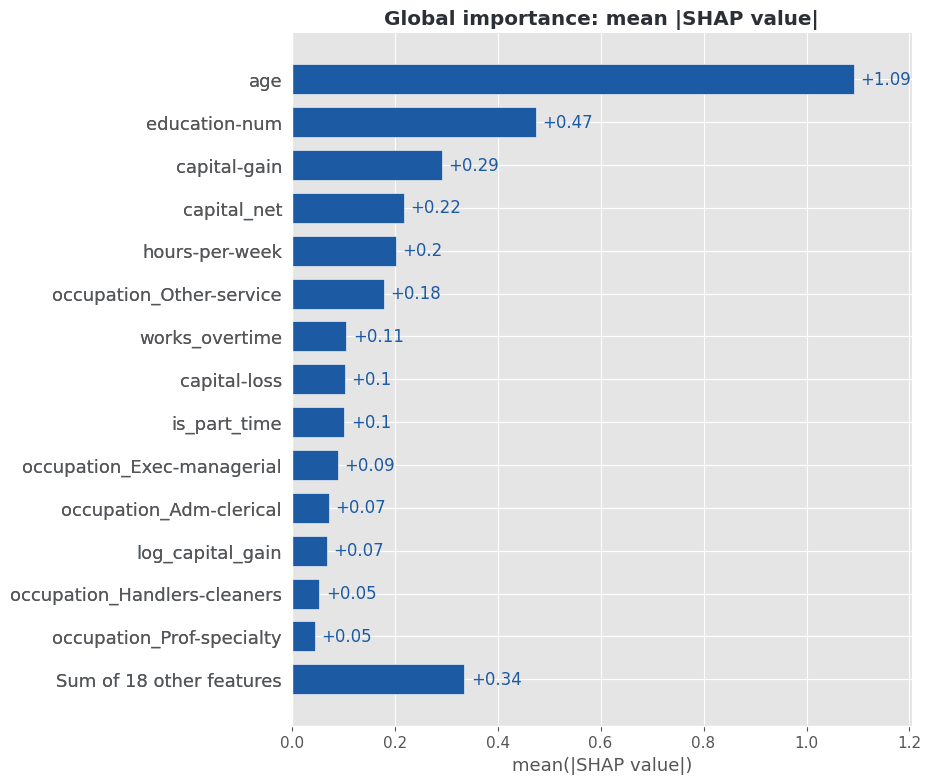

In [66]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Global importance: mean |SHAP value|")
plt.show()

In the **beeswarm** plot, each dot is one person: its position is the SHAP value and its colour the feature value (navy = high, pale = low).

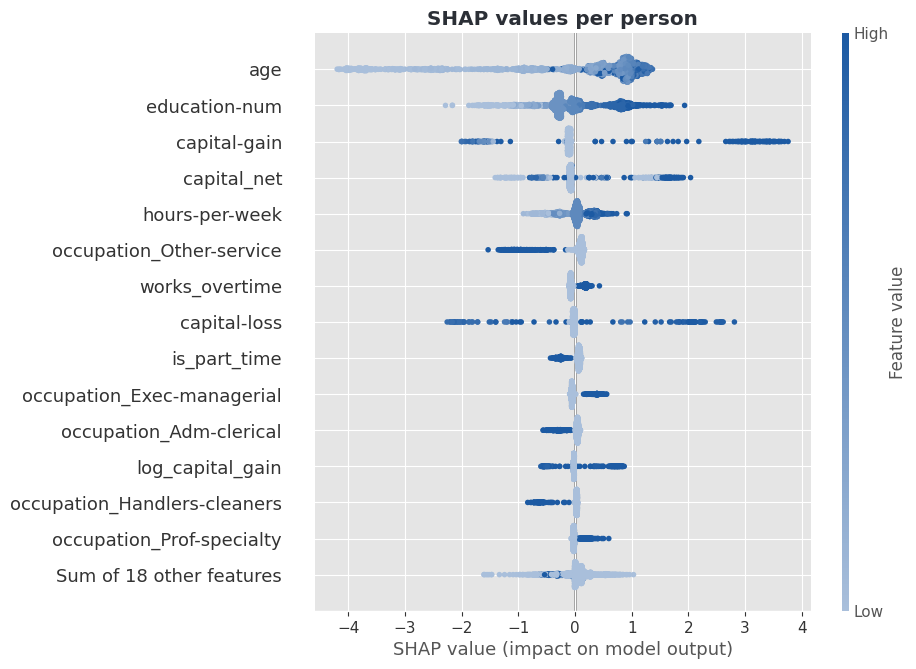

In [67]:
# slightly darker start than BLUES so that low values stay visible as dots on white
dots_cmap = LinearSegmentedColormap.from_list("agency_blues_dots", ["#A9BFDB", NAVY])
shap.plots.beeswarm(shap_values, max_display=15, show=False, color=dots_cmap)
plt.title("SHAP values per person")
plt.show()

In [68]:
global_importance = (
    pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names)
    .sort_values(ascending=False)
)
global_importance.head(15).round(3)

,0
age,1.092
education-num,0.474
capital-gain,0.291
capital_net,0.218
hours-per-week,0.202
occupation_Other-service,0.179
works_overtime,0.106
capital-loss,0.103
is_part_time,0.102
occupation_Exec-managerial,0.089


**Do the important features make business sense?**
Yes. All of them are legitimate pay factors: **age** (experience) comes first, then **education**, **capital gain** / `capital_net` (investment income, which we control for), **hours per week**, and **occupations** (`Other-service`, `Adm-clerical`, `Handlers-cleaners` push down; `Exec-managerial`, `Prof-specialty` push up). Older, more educated people working longer hours (navy dots on the right) are pushed towards >50K. Four of our five engineered features are in the top 15.

SHAP describes what the **model** uses, not what **causes** income.

### Explaining individual people

Four instructive cases: the most confident correct prediction on each side, a missed high earner (really >50K, low score) and a false alarm (really <=50K, high score). In a waterfall plot, start from the average output $E[f(X)]$; each bar adds one feature's contribution (navy pushes towards >50K, violet towards <=50K) up to the person's output $f(x)$.

In [69]:
raw_proba = final_pipe.predict_proba(shap_sample)[:, 1]
y_sample = y_val.loc[shap_sample.index].to_numpy()
positions = np.arange(len(shap_sample))

cases = {
    "Confident >50K (correct)": positions[y_sample == 1][np.argmax(raw_proba[y_sample == 1])],
    "Confident <=50K (correct)": positions[y_sample == 0][np.argmin(raw_proba[y_sample == 0])],
    "Missed high earner": positions[y_sample == 1][np.argmin(raw_proba[y_sample == 1])],
    "False alarm": positions[y_sample == 0][np.argmax(raw_proba[y_sample == 0])],
}

pd.DataFrame({
    "true_label": [y_sample[i] for i in cases.values()],
    "model_probability": [raw_proba[i].round(3) for i in cases.values()],
}, index=cases.keys())

,true_label,model_probability
Confident >50K (correct),1,0.999
Confident <=50K (correct),0,0.001
Missed high earner,1,0.084
False alarm,0,0.912



=== Confident >50K (correct) ===


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
41637,45,Private,102308,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,15024,0,60,United-States


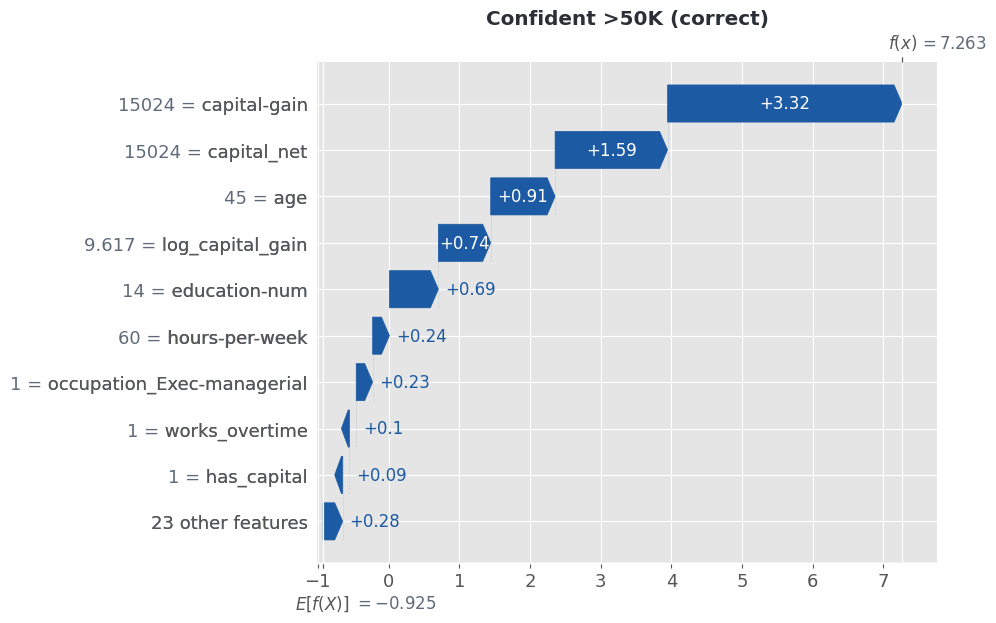


=== Confident <=50K (correct) ===


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
3058,17,Private,74706,11th,7,Never-married,Priv-house-serv,Own-child,White,Male,0,0,20,United-States


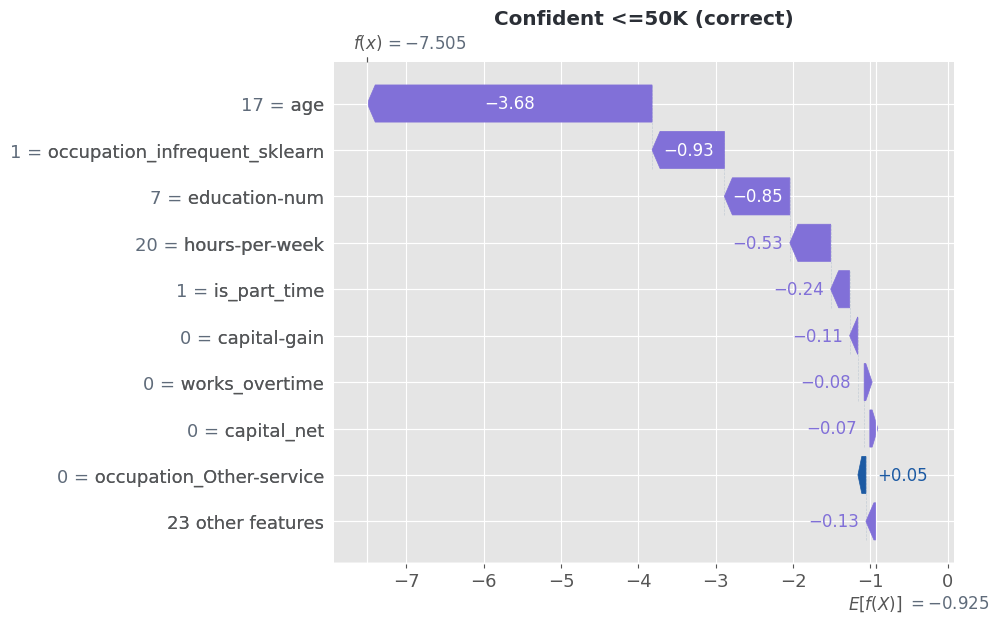


=== Missed high earner ===


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
42650,46,Private,100067,11th,7,Married-civ-spouse,Other-service,Wife,Black,Female,0,0,35,United-States


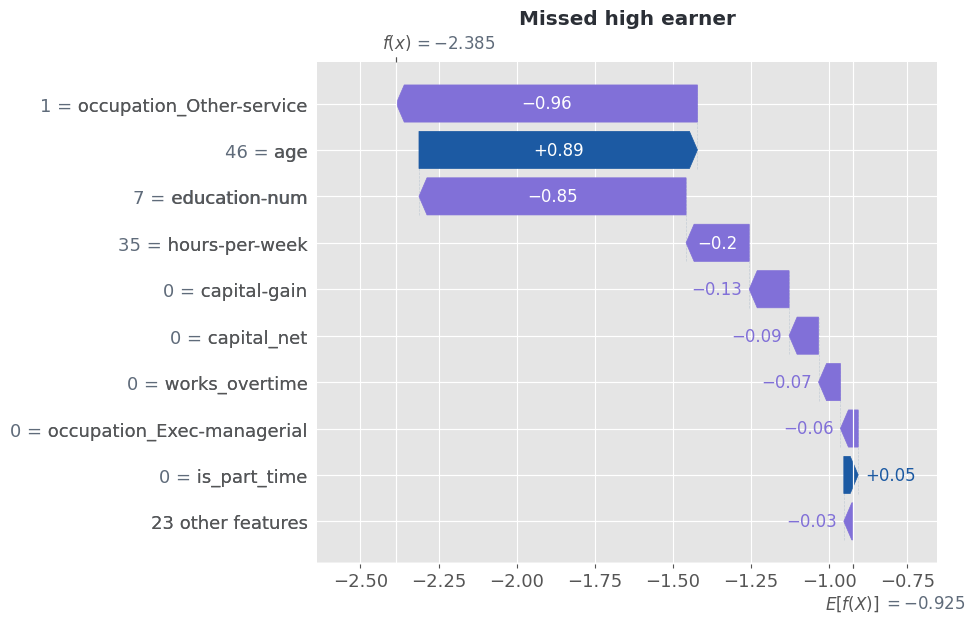


=== False alarm ===


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
30322,50,Self-emp-inc,104849,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,Asian-Pac-Islander,Male,0,0,40,India


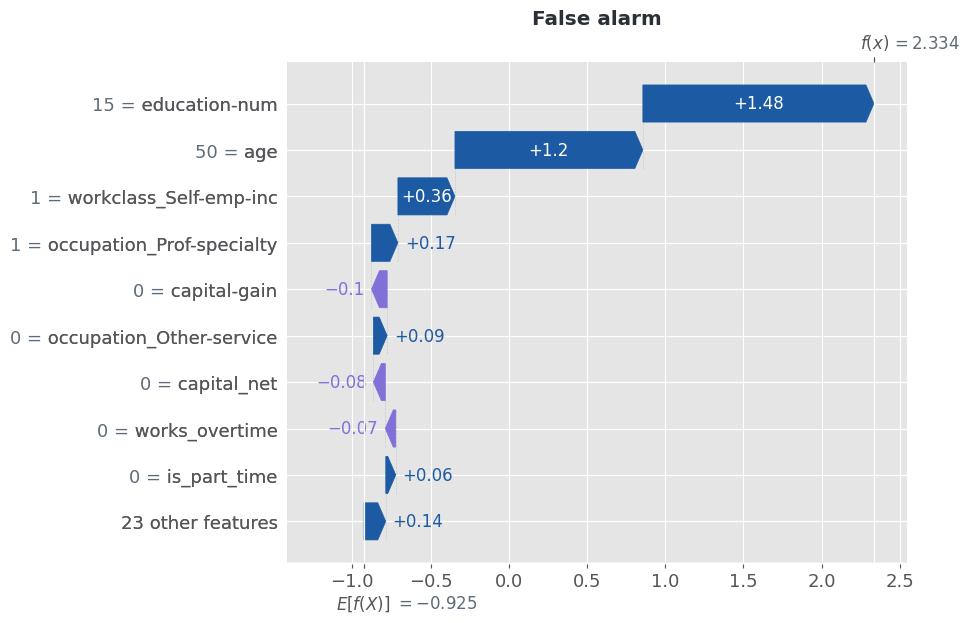

In [70]:
for title, i in cases.items():
    print(f"\n=== {title} ===")
    display(shap_sample.iloc[[i]])
    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(title)
    plt.show()

**What do the mistakes tell us?**
They are understandable. The missed high earner is a 46-year-old woman with an 11th-grade education, working 35 hours a week in `Other-service`: every job-related factor points to <=50K, so her income is very unusual for her profile. The false alarm is a 50-year-old self-employed person with a professional degree: everything predicts >50K, yet the income is lower. For a regulator this is exactly what a "potentially underpaid" flag looks like, but this person is self-employed, so there is no employer to blame; a real company audit only includes employees. Errors come from information missing from the data, so a flag is only a starting point for an inspector.

## Calibration

A model is **calibrated** if, among people who get a probability of 0.30, about 30% really earn >50K. For the regulator this is essential: a group's **expected** rate is the average of its probabilities, so inflated probabilities would make every group look underpaid.

- **Reliability curve:** mean predicted probability vs observed rate, per bin. Below the diagonal = probabilities too high.
- **Brier score:** mean squared error of the probabilities (lower is better).
- **ECE:** average gap between predicted and observed rates over the bins (0 is perfect).

Class weights make every high earner count about 3× more during training, which **inflates** the probabilities. Let's check.

In [71]:
def expected_calibration_error(y_true, y_proba, n_bins=10):
    y_true = np.asarray(y_true)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_proba, bin_edges[1:-1])   # bin number of each person

    ece = 0.0
    for b in range(n_bins):
        in_bin = bin_ids == b
        if in_bin.any():
            gap = abs(y_true[in_bin].mean() - y_proba[in_bin].mean())
            ece += in_bin.mean() * gap                 # weighted by the share of people in the bin
    return ece


def calibration_summary(name, y_true, y_proba):
    return pd.Series({
        "brier_score": brier_score_loss(y_true, y_proba),
        "ece": expected_calibration_error(y_true, y_proba),
        "mean_predicted_probability": y_proba.mean(),
        "observed_rate": np.mean(y_true),
        "pr_auc": average_precision_score(y_true, y_proba),
    }, name=name)

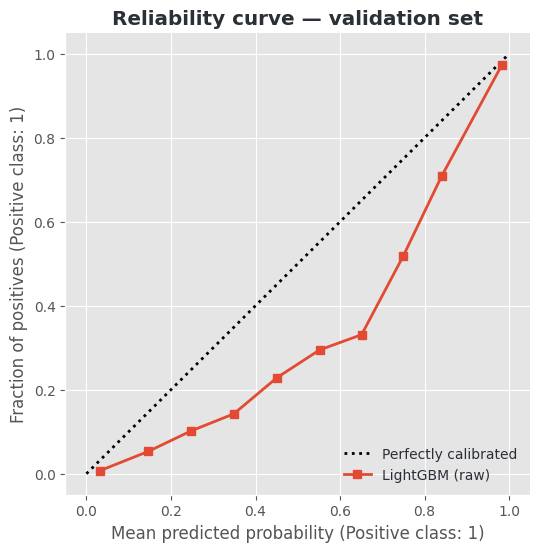

,raw
brier_score,0.1317
ece,0.1352
mean_predicted_probability,0.3744
observed_rate,0.2392
pr_auc,0.7763


In [72]:
val_proba_raw = final_pipe.predict_proba(X_val)[:, 1]

fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_val, val_proba_raw, n_bins=10, name=f"{FINAL_MODEL_NAME} (raw)", ax=ax)
ax.set_title("Reliability curve — validation set")
plt.show()

calibration_summary("raw", y_val, val_proba_raw).round(4)

The curve lies **below the diagonal**: the model predicts 0.37 on average while the real rate is 0.24 (ECE ≈ 0.13). It **over-estimates** the chance of earning >50K, the side effect of class weights. We would not trust these probabilities as they are; the ranking is still good, so we fix the probabilities, not the model.

### Recalibration

`CalibratedClassifierCV` learns a mapping from raw scores to calibrated probabilities, either a sigmoid curve (`"sigmoid"`) or a flexible increasing step function (`"isotonic"`). With `cv=5` it learns this mapping on **out-of-fold** predictions of the training set, so calibration never sees the validation or test sets. Calibration keeps the ranking, so AP barely changes.

In [73]:
calibrated_models = {}
summaries = [calibration_summary("raw", y_val, val_proba_raw)]

for method in ["sigmoid", "isotonic"]:
    calibrated = CalibratedClassifierCV(clone(final_pipe), method=method, cv=5)
    calibrated.fit(X_train, y_train)
    calibrated_models[method] = calibrated
    summaries.append(calibration_summary(method, y_val, calibrated.predict_proba(X_val)[:, 1]))

calibration_table = pd.DataFrame(summaries)
calibration_table.round(4)

,brier_score,ece,mean_predicted_probability,observed_rate,pr_auc
raw,0.1317,0.1352,0.3744,0.2392,0.7763
sigmoid,0.1054,0.0310,0.2363,0.2392,0.7762
isotonic,0.1030,0.0102,0.2364,0.2392,0.7748


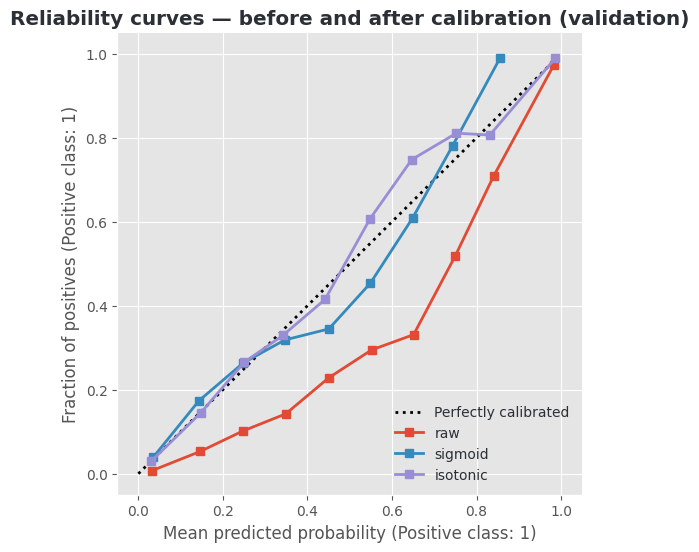

In [74]:
fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_val, val_proba_raw, n_bins=10, name="raw", ax=ax)
for method, calibrated in calibrated_models.items():
    CalibrationDisplay.from_predictions(
        y_val, calibrated.predict_proba(X_val)[:, 1], n_bins=10, name=method, ax=ax,
    )
ax.set_title("Reliability curves — before and after calibration (validation)")
plt.show()

In [75]:
CALIBRATION_METHOD = calibration_table["brier_score"].idxmin()
calibrated_model = calibrated_models[CALIBRATION_METHOD]
val_proba = calibrated_model.predict_proba(X_val)[:, 1]

print("Chosen calibration method:", CALIBRATION_METHOD)

Chosen calibration method: isotonic


After calibration the curves follow the diagonal, the mean probability matches the real rate, the Brier score drops (≈ 0.132 → 0.103) and the ECE falls to about 0.01, with no loss of ranking. **Isotonic** is clearly better than sigmoid here (ECE about three times lower) and we have plenty of data to fit it, so we keep it, even though the course advises the simpler method when the difference is small. From now on we use the calibrated probabilities.

### How many people support each point of the curve?

A point computed from a few dozen people is noisy, so we show the number of validation people per probability bin.

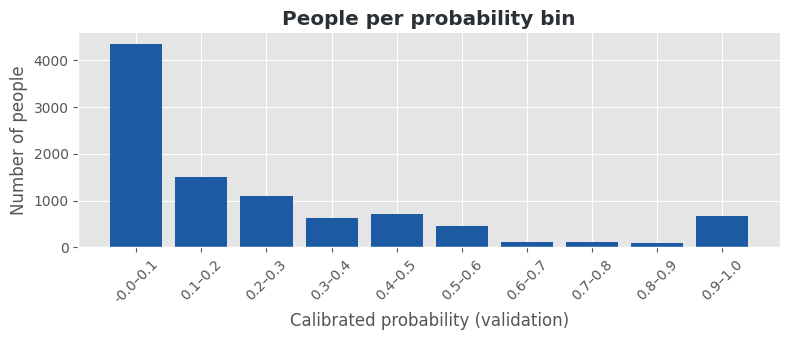

,n_people,mean_predicted,observed_rate
bin,,,
"(-0.001, 0.1]",4362,0.030,0.030
"(0.1, 0.2]",1512,0.148,0.146
"(0.2, 0.3]",1099,0.251,0.266
"(0.3, 0.4]",635,0.341,0.329
"(0.4, 0.5]",718,0.442,0.415
"(0.5, 0.6]",456,0.548,0.607
"(0.6, 0.7]",115,0.647,0.748
"(0.7, 0.8]",111,0.752,0.811
"(0.8, 0.9]",93,0.831,0.806


In [76]:
bins = np.linspace(0, 1, 11)
bin_table = (
    pd.DataFrame({"bin": pd.cut(val_proba, bins, include_lowest=True), "y": y_val.to_numpy(), "p": val_proba})
    .groupby("bin", observed=False)
    .agg(n_people=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"))
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(len(bin_table)), bin_table["n_people"], color=NAVY)
ax.set_xticks(range(len(bin_table)), [f"{b.left:.1f}–{b.right:.1f}" for b in bin_table.index], rotation=45)
ax.set_xlabel("Calibrated probability (validation)")
ax.set_ylabel("Number of people")
ax.set_title("People per probability bin")
plt.tight_layout()
plt.show()

bin_table.round(3)

Most people get a low probability: the first bin holds several thousand people, the bins above 0.5 only a few dozen to a few hundred each. The left part of the curve is precise; the high-probability region, where individual flags are raised, is noisier.

## Decision rule for individual flags

An employee whose profile makes >50K **more likely than not** (calibrated probability ≥ 0.5) but who earns <=50K is flagged as **potentially underpaid**. A flag may trigger an inspection and the agency has a limited number of inspectors, so **precision** matters more than catching every case. The threshold only affects individual flags; the group audit uses the probabilities directly.

In [77]:
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)

best = np.argmax(f1_scores[:-1])           # the last point has no threshold
F1_THRESHOLD = thresholds[best]

THRESHOLD = 0.5                            # "more likely than not" on calibrated probabilities
val_pred = (val_proba >= THRESHOLD).astype(int)

print(f"Threshold maximising F1: {F1_THRESHOLD:.3f} | precision {precisions[best]:.3f} | recall {recalls[best]:.3f} | F1 {f1_scores[best]:.3f}")
print(f"Chosen threshold: {THRESHOLD}        | precision {precision_score(y_val, val_pred):.3f} | recall {recall_score(y_val, val_pred):.3f} | F1 {f1_score(y_val, val_pred):.3f}")

Threshold maximising F1: 0.391 | precision 0.684 | recall 0.646 | F1 0.664
Chosen threshold: 0.5        | precision 0.824 | recall 0.509 | F1 0.629


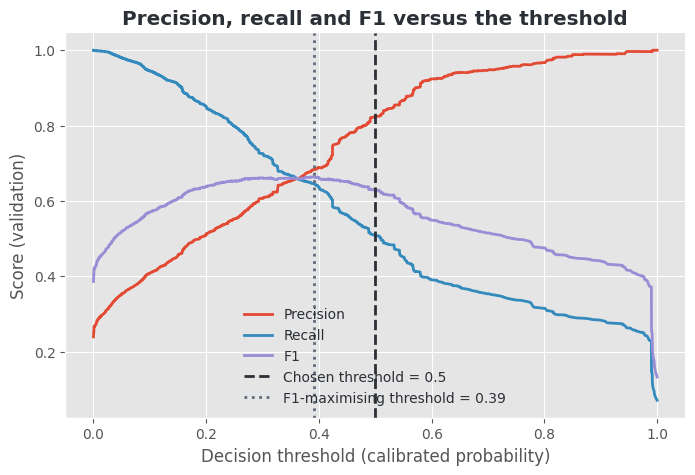

In [78]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.plot(thresholds, f1_scores[:-1], label="F1")
plt.axvline(THRESHOLD, linestyle="--", color=INK, label=f"Chosen threshold = {THRESHOLD}")
plt.axvline(F1_THRESHOLD, linestyle=":", color=STEEL, label=f"F1-maximising threshold = {F1_THRESHOLD:.2f}")
plt.xlabel("Decision threshold (calibrated probability)")
plt.ylabel("Score (validation)")
plt.title("Precision, recall and F1 versus the threshold")
plt.legend()
plt.show()

At 0.5, about **82%** of the people expected to earn >50K really do, for a recall of about 0.51. The F1-maximising threshold (≈ 0.39) would find more (recall ≈ 0.65) with more false alarms (precision ≈ 0.68): we keep 0.5.

## Final evaluation on the test set

Every choice is now fixed: columns, model, hyperparameters, calibration, threshold. We evaluate **once** on the untouched test set.

We do **not** refit on train + validation first (the course protocol does): validation was used to choose the calibration and the threshold, and refitting would change the model after those choices. The gain from 20% more data would be small.

In [79]:
test_proba = calibrated_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

val_pred = (val_proba >= THRESHOLD).astype(int)

final_results = pd.DataFrame({
    "validation": classification_metrics(y_val, val_pred, val_proba),
    "test": classification_metrics(y_test, test_pred, test_proba),
})
final_results.loc["brier_score"] = [brier_score_loss(y_val, val_proba), brier_score_loss(y_test, test_proba)]
final_results.loc["ece"] = [expected_calibration_error(y_val, val_proba), expected_calibration_error(y_test, test_proba)]
final_results.round(4)

,validation,test
accuracy,0.8565,0.8539
precision,0.8240,0.8183
recall,0.5088,0.5009
f1,0.6291,0.6214
roc_auc,0.8925,0.8933
pr_auc,0.7748,0.7766
brier_score,0.1030,0.1025
ece,0.0102,0.0087


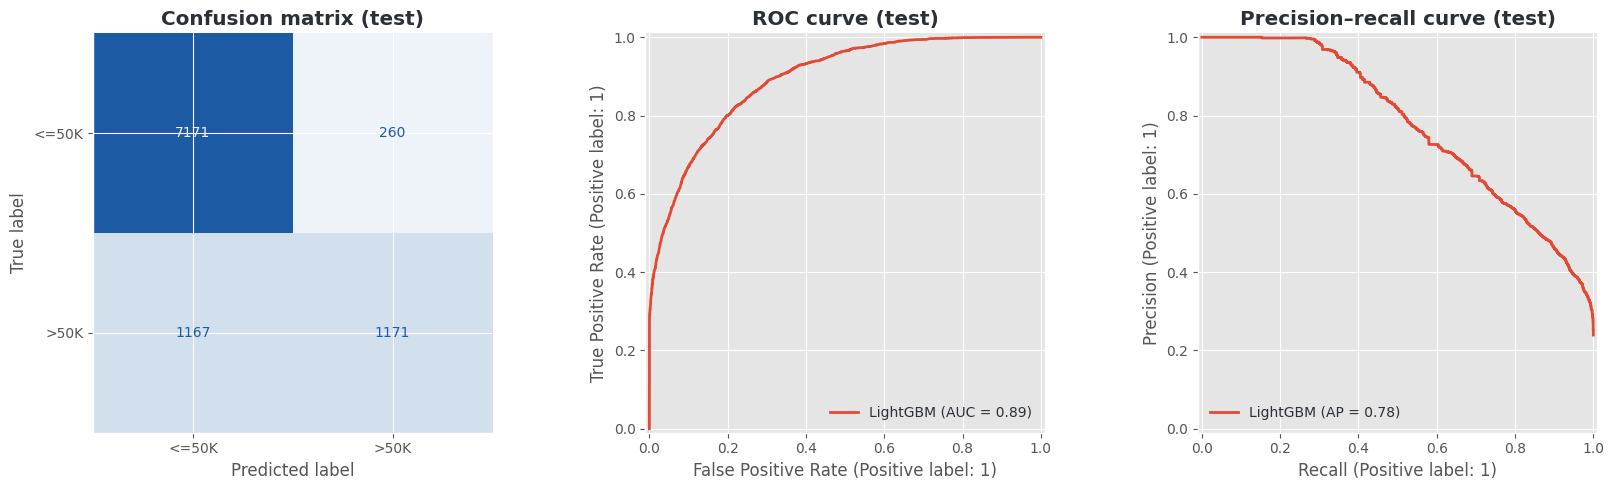

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["<=50K", ">50K"], ax=axes[0], colorbar=False, cmap=BLUES,
)
axes[0].set_title("Confusion matrix (test)")

RocCurveDisplay.from_predictions(y_test, test_proba, name=FINAL_MODEL_NAME, ax=axes[1])
axes[1].set_title("ROC curve (test)")

PrecisionRecallDisplay.from_predictions(y_test, test_proba, name=FINAL_MODEL_NAME, ax=axes[2])
axes[2].set_title("Precision–recall curve (test)")

plt.tight_layout()
plt.show()

Test and validation results are almost identical (ROC-AUC 0.89, AP ≈ 0.78, precision 0.82, ECE below 0.01): our choices did not overfit the validation set, and these are honest estimates for new people from the same population.

## Fairness audit

Two questions must be kept apart:
1. **Is the pay fair?** Our definition is "equal pay for equal work": people with the same job-related profile should have the same chance of earning >50K, whatever their group. We measure it with the **unexplained gap** = actual rate − expected rate (mean calibrated probability).
2. **Is our model fair?** It must give the **same prediction to the same profile**, whatever the person's sex or race. That is why sex, race and their proxies are not inputs: this is our **mitigation**, tested below.

We also report the classic fairness metrics of the yes/no predictions:

| Definition | Requirement | Metric (0 = equal) |
|---|---|---|
| Demographic parity | same share predicted >50K in each group | `demographic_parity_difference` |
| Equal opportunity | same true positive rate | `equal_opportunity_difference` |
| Equalized odds | same true and false positive rates | `equalized_odds_difference` |

For our model, a false positive is a person expected to earn >50K who earns less: a **potentially underpaid** employee. A lower precision for one group is therefore evidence about the **pay**, not a defect of the model.

### Classic fairness metrics

In [81]:
fairness_metrics = {
    "count": lambda y_true, y_pred: len(y_true),
    "base_rate": lambda y_true, y_pred: np.mean(y_true),     # actual share earning >50K
    "selection_rate": selection_rate,                        # share predicted >50K
    "true_positive_rate": true_positive_rate,
    "false_positive_rate": false_positive_rate,              # = expected >50K but paid <=50K
    "precision": lambda y_true, y_pred: precision_score(y_true, y_pred, zero_division=0),
}


def fairness_report(y_true, y_pred, sensitive):
    frame = MetricFrame(metrics=fairness_metrics, y_true=y_true, y_pred=y_pred,
                        sensitive_features=sensitive)
    gaps = pd.Series({
        "demographic_parity_difference": demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive),
        "equal_opportunity_difference": equal_opportunity_difference(y_true, y_pred, sensitive_features=sensitive),
        "equalized_odds_difference": equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive),
    })
    return frame, gaps


frame_sex, gaps_sex = fairness_report(y_test, test_pred, X_test["sex"])
display(frame_sex.by_group.round(3))
gaps_sex.round(3)

,count,base_rate,selection_rate,true_positive_rate,false_positive_rate,precision
sex,,,,,,
Female,3259.0,0.111,0.078,0.465,0.029,0.664
Male,6510.0,0.304,0.181,0.507,0.039,0.851


,0
demographic_parity_difference,0.103
equal_opportunity_difference,0.042
equalized_odds_difference,0.042


In [82]:
frame_race, gaps_race = fairness_report(y_test, test_pred, X_test["race"])
display(frame_race.by_group.round(3))
gaps_race.round(3)

,count,base_rate,selection_rate,true_positive_rate,false_positive_rate,precision
race,,,,,,
Amer-Indian-Eskimo,96.0,0.135,0.052,0.385,0.000,1.000
Asian-Pac-Islander,311.0,0.264,0.167,0.451,0.066,0.712
Black,968.0,0.133,0.075,0.488,0.012,0.863
Other,82.0,0.122,0.061,0.500,0.000,1.000
White,8312.0,0.253,0.156,0.504,0.038,0.819


,0
demographic_parity_difference,0.115
equal_opportunity_difference,0.120
equalized_odds_difference,0.120


- **Demographic parity** is not satisfied (gap ≈ 0.10): the model expects >50K for 18% of men and 8% of women, purely because their job-related profiles differ (hours, part-time, occupations). This is smaller than the real gap (30% vs 11%).
- **True and false positive rates** are close between sexes (TPR 0.47 vs 0.51, FPR ≈ 0.03–0.04).
- The telling number is **precision**: among people expected to earn >50K, **85% of men** really do, but only **66% of women**. Women whose qualifications predict a high income are much more often not paid it.
- For **race**, the largest gap comes from the tiny `Amer-Indian-Eskimo` group (96 people), which is unreliable. Black employees expected to earn >50K have a *higher* precision (0.86) than White employees (0.82): any race gap is not concentrated among high expected incomes.

### Actual vs expected: the pay-equity audit

For each group: the actual and expected share of high earners, the **unexplained gap** in percentage points with a **95% bootstrap confidence interval** (we resample the group 1,000 times), and the share of employees expected to earn >50K who do not (`underpaid_rate`). Groups under 100 people are marked as too small.

In [83]:
def bootstrap_gap_ci(actual, expected, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(actual)
    gaps = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)            # resample the group's people with replacement
        gaps.append(actual[idx].mean() - expected[idx].mean())
    return np.percentile(gaps, [2.5, 97.5])


def pay_equity_audit(y_true, y_proba, groups, threshold=THRESHOLD, min_size=100):
    data = pd.DataFrame({
        "group": np.asarray(groups).astype(str),
        "actual": np.asarray(y_true),
        "expected": np.asarray(y_proba),
    })
    rows = []
    for group, part in data.groupby("group"):
        actual, expected = part["actual"].to_numpy(), part["expected"].to_numpy()
        low, high = bootstrap_gap_ci(actual, expected)
        expected_high = expected >= threshold
        rows.append({
            "group": group,
            "n": len(part),
            "actual_rate": actual.mean(),
            "expected_rate": expected.mean(),
            "unexplained_gap_pts": 100 * (actual.mean() - expected.mean()),
            "ci_low_pts": 100 * low,
            "ci_high_pts": 100 * high,
            "underpaid_rate": (actual[expected_high] == 0).mean() if expected_high.any() else np.nan,
            "enough_data": len(part) >= min_size,
        })
    return pd.DataFrame(rows).set_index("group").sort_values("unexplained_gap_pts")

In [84]:
audit_sex = pay_equity_audit(y_test, test_proba, X_test["sex"])
audit_sex.round(3)

,n,actual_rate,expected_rate,unexplained_gap_pts,ci_low_pts,ci_high_pts,underpaid_rate,enough_data
group,,,,,,,,
Female,3259,0.111,0.165,-5.405,-6.266,-4.562,0.336,True
Male,6510,0.304,0.271,3.309,2.433,4.160,0.149,True


In [85]:
audit_race = pay_equity_audit(y_test, test_proba, X_test["race"])
audit_race.round(3)

,n,actual_rate,expected_rate,unexplained_gap_pts,ci_low_pts,ci_high_pts,underpaid_rate,enough_data
group,,,,,,,,
Black,968,0.133,0.167,-3.400,-4.903,-1.936,0.137,True
Amer-Indian-Eskimo,96,0.135,0.164,-2.891,-8.078,3.030,0.000,False
Other,82,0.122,0.148,-2.576,-7.100,2.992,0.000,False
White,8312,0.253,0.244,0.891,0.204,1.603,0.181,True
Asian-Pac-Islander,311,0.264,0.254,0.961,-2.904,4.972,0.288,True


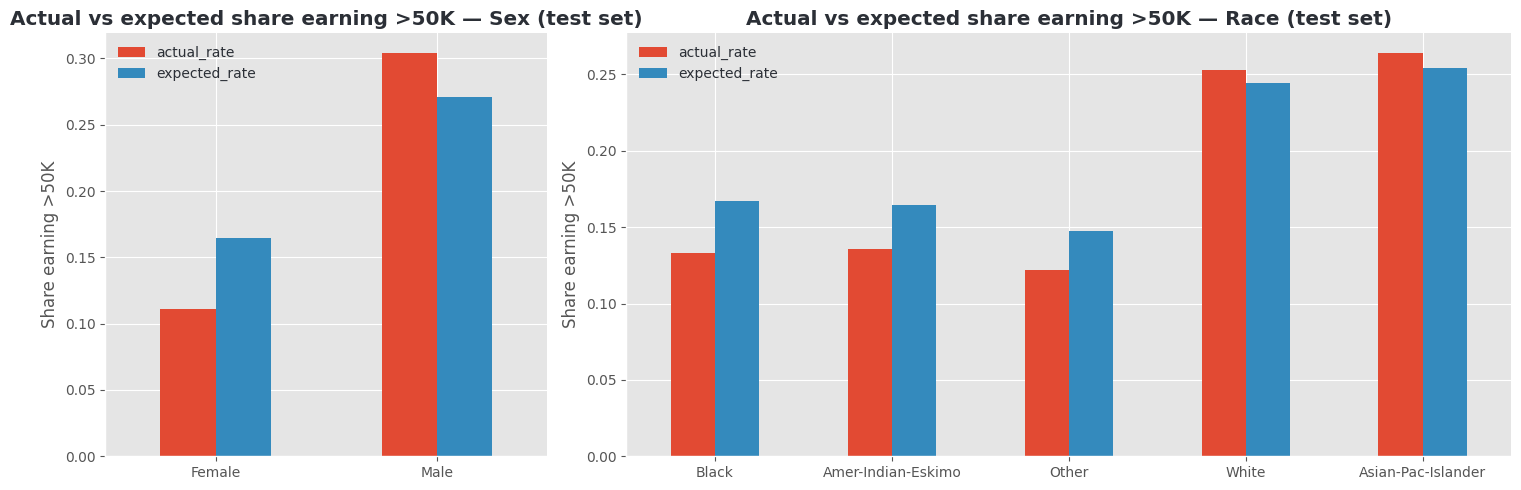

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})

for ax, (title, table) in zip(axes, [("Sex", audit_sex), ("Race", audit_race)]):
    table[["actual_rate", "expected_rate"]].plot(kind="bar", ax=ax)
    ax.set_title(f"Actual vs expected share earning >50K — {title} (test set)")
    ax.set_ylabel("Share earning >50K")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

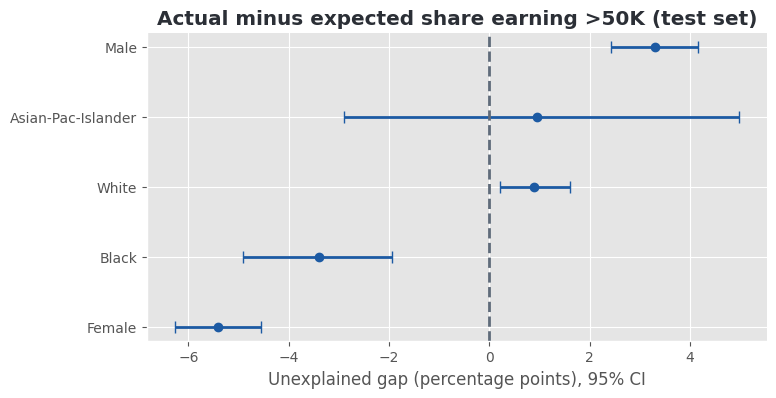

In [87]:
# Unexplained gap with its 95% confidence interval (groups with enough data)
audit_all = pd.concat([audit_sex.assign(attribute="sex"), audit_race.assign(attribute="race")])
shown = audit_all[audit_all["enough_data"]].sort_values("unexplained_gap_pts")

plt.figure(figsize=(8, 4))
plt.errorbar(
    shown["unexplained_gap_pts"], range(len(shown)), color=NAVY,
    xerr=[shown["unexplained_gap_pts"] - shown["ci_low_pts"], shown["ci_high_pts"] - shown["unexplained_gap_pts"]],
    fmt="o", capsize=4,
)
plt.yticks(range(len(shown)), shown.index)
plt.axvline(0, color=STEEL, linestyle="--")
plt.xlabel("Unexplained gap (percentage points), 95% CI")
plt.title("Actual minus expected share earning >50K (test set)")
plt.show()

**Is there an unexplained gap?**
- **Sex: yes.** Women earn >50K **5.4 points less often** than their profiles predict (11.1% vs 16.5%, 95% CI −6.3 to −4.6); men 3.3 points more. Among women expected to earn >50K, 34% do not, versus 15% of men.
- **Race:** Black employees earn **3.4 points less** than expected (13.3% vs 16.7%, CI −4.9 to −1.9). White employees are slightly above expectation (+0.9, significant only because the group is large) and Asian-Pac-Islander employees close to it. The two smallest groups are too small to conclude. Among Black employees expected to earn >50K, only 14% do not (18% for White employees): this gap is spread over moderate probabilities, so it shows up in the group comparison rather than in individual flags.

**Does it prove discrimination?**
No. The gap is **not explained by the factors in our data**; unobserved factors (seniority, exact job, region…) could explain part of it, and the factors we control for (occupation, hours) may themselves reflect discrimination. A significant gap is a strong reason to **open an investigation**, not a verdict.

### Mitigation: before / after on the test set

Our mitigation is a **pre-processing** technique: removing the protected attributes and their proxies from the inputs. To measure its effect we build the **"before"** model: the same tuned model, calibration and threshold, but trained on **all** columns, including sex, race, national origin, marital status and relationship.

In [88]:
naive_pipe = clone(final_pipe).set_params(features__drop_columns=NOT_USEFUL_COLUMNS)

naive_model = CalibratedClassifierCV(naive_pipe, method=CALIBRATION_METHOD, cv=5)
naive_model.fit(X_train, y_train)

naive_proba = naive_model.predict_proba(X_test)[:, 1]
naive_pred = (naive_proba >= THRESHOLD).astype(int)

naive_audit_sex = pay_equity_audit(y_test, naive_proba, X_test["sex"])
naive_audit_race = pay_equity_audit(y_test, naive_proba, X_test["race"])
naive_audit_sex.round(3)

,n,actual_rate,expected_rate,unexplained_gap_pts,ci_low_pts,ci_high_pts,underpaid_rate,enough_data
group,,,,,,,,
Female,3259,0.111,0.109,0.153,-0.570,0.917,0.183,True
Male,6510,0.304,0.301,0.234,-0.617,0.996,0.217,True


In [89]:
def summary_row(y_proba, y_pred, audit_sex, audit_race):
    _, sex_gaps = fairness_report(y_test, y_pred, X_test["sex"])
    return pd.Series({
        "roc_auc": roc_auc_score(y_test, y_proba),
        "pr_auc": average_precision_score(y_test, y_proba),
        "brier_score": brier_score_loss(y_test, y_proba),
        "f1": f1_score(y_test, y_pred),
        "demographic_parity_difference_sex": sex_gaps["demographic_parity_difference"],
        "equalized_odds_difference_sex": sex_gaps["equalized_odds_difference"],
        "unexplained_gap_women_pts": audit_sex.loc["Female", "unexplained_gap_pts"],
        "unexplained_gap_men_pts": audit_sex.loc["Male", "unexplained_gap_pts"],
        "unexplained_gap_black_pts": audit_race.loc["Black", "unexplained_gap_pts"],
    })


before_after = pd.DataFrame({
    "before: all columns": summary_row(naive_proba, naive_pred, naive_audit_sex, naive_audit_race),
    "after: job-related only": summary_row(test_proba, test_pred, audit_sex, audit_race),
})
before_after.round(3)

,before: all columns,after: job-related only
roc_auc,0.930,0.893
pr_auc,0.834,0.777
brier_score,0.087,0.103
f1,0.721,0.621
demographic_parity_difference_sex,0.187,0.103
equalized_odds_difference_sex,0.114,0.042
unexplained_gap_women_pts,0.153,-5.405
unexplained_gap_men_pts,0.234,3.309
unexplained_gap_black_pts,1.101,-3.400


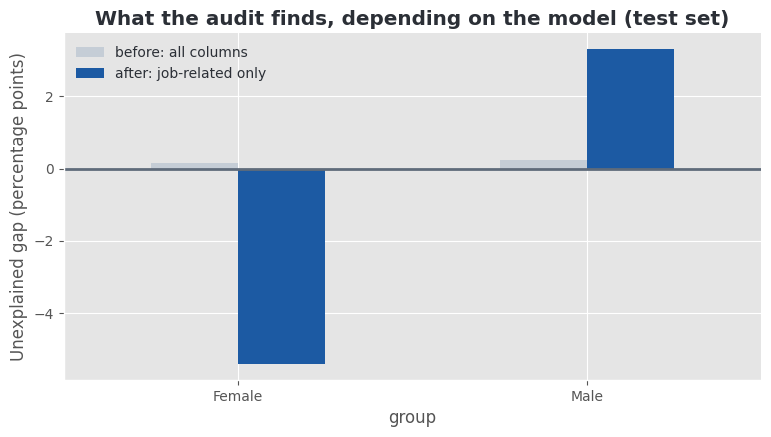

In [90]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({
    "before: all columns": naive_audit_sex["unexplained_gap_pts"],
    "after: job-related only": audit_sex["unexplained_gap_pts"],
}).plot(kind="bar", ax=ax, color=[SILVER, NAVY])      # grey = before (reference), navy = our model
ax.axhline(0, color=STEEL)
ax.set_ylabel("Unexplained gap (percentage points)")
ax.set_title("What the audit finds, depending on the model (test set)")
ax.tick_params(axis="x", rotation=0)
plt.show()

**What does the mitigation change, and what does it cost?**
Removing the protected attributes costs some accuracy (ROC-AUC 0.93 → 0.89, AP 0.83 → 0.78, F1 0.72 → 0.62), but makes the model fairer on the classic metrics (demographic-parity gap 0.19 → 0.10, equalized-odds gap 0.11 → 0.04). Above all, it **changes the audit**: with the "before" model the unexplained gap is about **0** for women and for Black employees; with ours it is **−5.4** and **−3.4** points.

**Why is the "before" model dangerous for a regulator?**
It is more accurate **because it has learned the discrimination**: it expects lower pay for women and Black employees, so it finds them paid exactly as expected and would declare every employer fair. The reference model must describe what people *should* earn for their job, not what they *do* earn given their sex and race.

### Why not a post-processing method such as `ThresholdOptimizer`?

Post-processing sets **different thresholds per group** so that error rates become equal. That suits a model that **decides** about people (hiring, credit). For a regulator it would **erase the evidence**: the extra "errors" for women are the underpayment signal. It would also require using sex and race at prediction time, the opposite of the principle we enforce.

### Proxy check: do the inputs still "know" a person's sex?

We train a simple classifier to predict sex from the model's inputs (ROC-AUC 0.5 = no information, 1.0 = perfect).

In [91]:
model_inputs = final_pipe[:-1].transform(X_train)          # the exact inputs of our model
is_female = (X_train["sex"] == "Female").astype(int)

proxy_auc = cross_val_score(
    LogisticRegression(max_iter=2000), model_inputs, is_female, cv=5, scoring="roc_auc",
).mean()
print(f"ROC-AUC for predicting sex from the model inputs: {proxy_auc:.3f}")

ROC-AUC for predicting sex from the model inputs: 0.791


The inputs predict sex with a ROC-AUC of about **0.79**, mainly through **occupation** and **hours**. This is intended under "equal pay for equal work" (a part-time employee is expected to earn less). But it means our gap only measures unequal pay **for comparable jobs**: if women are kept out of well-paid jobs, that discrimination is "explained" by occupation and does not appear. Our gap is a **lower bound**.

### Sensitivity check: does the audit depend on the capital columns?

`capital-gain` and `capital-loss` are part of the income that defines the target (partial target leakage, see Part 1). We retrain the same model **without** them and their engineered features, and repeat the audit.

In [92]:
CAPITAL_COLUMNS = ["capital-gain", "capital-loss"]


class DropCapitalFeatures(BaseEstimator, TransformerMixin):
    # Removes the capital columns and the features engineered from them
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        engineered = ["capital_net", "has_capital", "log_capital_gain"]
        return X.drop(columns=[c for c in CAPITAL_COLUMNS + engineered if c in X.columns])


no_capital_pipe = clone(final_pipe)
no_capital_pipe.steps.insert(1, ("drop_capital", DropCapitalFeatures()))   # right after feature engineering

no_capital_model = CalibratedClassifierCV(no_capital_pipe, method=CALIBRATION_METHOD, cv=5)
no_capital_model.fit(X_train, y_train)
no_capital_proba = no_capital_model.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC without capital columns: {roc_auc_score(y_test, no_capital_proba):.3f} "
      f"(with: {roc_auc_score(y_test, test_proba):.3f})")

sensitivity = pd.concat({
    "with capital columns": pd.concat([audit_sex, audit_race])[["unexplained_gap_pts", "ci_low_pts", "ci_high_pts"]],
    "without capital columns": pd.concat([
        pay_equity_audit(y_test, no_capital_proba, X_test["sex"]),
        pay_equity_audit(y_test, no_capital_proba, X_test["race"]),
    ])[["unexplained_gap_pts", "ci_low_pts", "ci_high_pts"]],
}, axis=1)
sensitivity.loc[["Female", "Male", "Black", "White", "Asian-Pac-Islander"]].round(2)

Test ROC-AUC without capital columns: 0.846 (with: 0.893)


with capital columns                         \
                    unexplained_gap_pts ci_low_pts ci_high_pts   
group                                                            
Female                            -5.40      -6.27       -4.56   
Male                               3.31       2.43        4.16   
Black                             -3.40      -4.90       -1.94   
White                              0.89       0.20        1.60   
Asian-Pac-Islander                 0.96      -2.90        4.97   

                   without capital columns                         
                       unexplained_gap_pts ci_low_pts ci_high_pts  
group                                                              
Female                               -6.56      -7.55       -5.51  
Male                                  4.02       3.04        4.99  
Black                                -3.76      -5.63       -1.96  
White                                 1.08       0.34        1.92  
Asian-Pac-Islander                    0.35      -3.97        4.53

Without the capital columns the model loses predictive power (ROC-AUC drops by about 0.05), but the **conclusion is unchanged**: the gaps for women and Black employees stay negative and significant, and become slightly larger, because capital income is more frequent among men. The audit does not rely on the leaky columns; keeping them is the conservative choice, as it gives employers the benefit of the doubt for income they do not pay.

### Log the final evaluation and the audit in MLflow

In [93]:
with mlflow.start_run(run_name=f"{FINAL_MODEL_NAME} — final test & audit"):
    mlflow.set_tags({"stage": "final_test", "model_type": FINAL_MODEL_NAME, "source_run_id": final_run_id})
    mlflow.log_params({
        "calibration_method": CALIBRATION_METHOD,
        "threshold": THRESHOLD,
        "excluded_columns": ", ".join(REFERENCE_DROP),
        "fairness_mitigation": "pre-processing: protected attributes and proxies removed",
    })
    mlflow.log_metrics({f"test_{k}": v for k, v in final_results["test"].items()})
    mlflow.log_metrics({f"test_{k}_sex": v for k, v in gaps_sex.items()})
    mlflow.log_metrics({
        "no_capital_test_roc_auc": roc_auc_score(y_test, no_capital_proba),
        "unexplained_gap_women_pts": audit_sex.loc["Female", "unexplained_gap_pts"],
        "unexplained_gap_men_pts": audit_sex.loc["Male", "unexplained_gap_pts"],
        "unexplained_gap_black_pts": audit_race.loc["Black", "unexplained_gap_pts"],
        "naive_unexplained_gap_women_pts": naive_audit_sex.loc["Female", "unexplained_gap_pts"],
        "proxy_auc_sex": proxy_auc,
    })
    mlflow.log_table(audit_sex.reset_index(), "audit_by_sex.json")
    mlflow.log_table(audit_race.reset_index(), "audit_by_race.json")
    mlflow.log_table(before_after.reset_index(names="metric"), "mitigation_before_after.json")
    mlflow.log_table(global_importance.reset_index(name="mean_abs_shap").rename(columns={"index": "feature"}),
                     "shap_global_importance.json")
    mlflow.sklearn.log_model(calibrated_model, name="calibrated_model", serialization_format="cloudpickle")

print("Final evaluation and audit logged.")

2026/10/18 18:38:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Final evaluation and audit logged.


In [94]:
if DRIVE_BACKUP_DIR is not None:
    shutil.copytree(MLFLOW_DIR, DRIVE_BACKUP_DIR, dirs_exist_ok=True)
    print("MLflow data copied to", DRIVE_BACKUP_DIR)
elif IN_COLAB:
    # No Drive: zip the runs and download them to your computer instead
    from google.colab import files
    archive = shutil.make_archive("/content/mlflow_backup", "zip", MLFLOW_DIR)
    files.download(archive)
else:
    print("Not in Colab: MLflow data is already saved in", MLFLOW_DIR)

MLflow data copied to /content/drive/MyDrive/Supervised Learning & Model Engineering/Final Project/Code adapted to problematic/mlflow


# Part 5 — Serving the Model as an API

An inspector sends a company's **employee records** (job information, actual pay level, sex and race) and the API answers:
- `POST /predict` → each employee's probability of earning >50K, expected from the job profile;
- `POST /audit` → for each sex and race group, actual vs expected rates, the unexplained gap with its confidence interval, and the potentially underpaid employees;
- `GET /health` → a check that the service runs.

Sex and race are used only to **group** the results; the pipeline drops them before the model.

We use **FastAPI** (a Python library for web APIs that checks input data with **Pydantic**), **TestClient** (to call the API from this notebook without a server) and **uvicorn** (to run it as a real server).

## Export the model

The API must not depend on MLflow or on this notebook, so we save the calibrated pipeline (`audit_model.pkl`, with cloudpickle) and its settings (`model_info.json`) in a `serving/` folder.

In [95]:
SERVING_DIR = "serving"
os.makedirs(SERVING_DIR, exist_ok=True)

with open(f"{SERVING_DIR}/audit_model.pkl", "wb") as f:
    cloudpickle.dump(calibrated_model, f)

model_info = {
    "model_type": FINAL_MODEL_NAME,
    "calibration_method": CALIBRATION_METHOD,
    "threshold": THRESHOLD,
    "excluded_columns": list(REFERENCE_DROP),
    "test_roc_auc": float(final_results.loc["roc_auc", "test"]),
}
with open(f"{SERVING_DIR}/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

model_info

{'model_type': 'LightGBM',
 'calibration_method': 'isotonic',
 'threshold': 0.5,
 'excluded_columns': ['sex',
  'race',
  'native-country',
  'relationship',
  'marital-status',
  'fnlwgt',
  'education'],
 'test_roc_auc': 0.8932593605107682}

## Write the API

The next cell **writes a normal Python file**, `serving/audit_api.py` (that is what `%%writefile` does). Pydantic models describe the expected input (e.g. `age` between 16 and 100) and reject invalid requests automatically; each endpoint is a function decorated with `@app.get` or `@app.post`.

In [96]:
%%writefile serving/audit_api.py
"""Pay-equity audit API.

Run locally with:   uvicorn audit_api:app --reload   (from inside the serving/ folder)
Then open http://127.0.0.1:8000/docs for the interactive documentation.
"""
import json
from pathlib import Path
from typing import List, Optional

import cloudpickle
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict, Field

HERE = Path(__file__).parent
MIN_GROUP_SIZE = 30          # smaller groups are reported but marked as too small

with open(HERE / "audit_model.pkl", "rb") as f:
    MODEL = cloudpickle.load(f)
with open(HERE / "model_info.json") as f:
    INFO = json.load(f)
THRESHOLD = INFO["threshold"]


# ---------- input format ----------
class Employee(BaseModel):
    model_config = ConfigDict(populate_by_name=True)

    # job-related profile: the only information used by the model
    age: int = Field(ge=16, le=100)
    workclass: Optional[str] = None
    education_num: int = Field(alias="education-num", ge=1, le=16)
    occupation: Optional[str] = None
    capital_gain: float = Field(0, alias="capital-gain", ge=0)
    capital_loss: float = Field(0, alias="capital-loss", ge=0)
    hours_per_week: float = Field(alias="hours-per-week", gt=0, le=99)

    # used only to group the audit results, never by the model
    sex: Optional[str] = None
    race: Optional[str] = None

    # actual pay level (needed for /audit): 1 if the employee earns >50K
    income_over_50k: Optional[int] = Field(None, ge=0, le=1)


class PredictRequest(BaseModel):
    employees: List[Employee]


class AuditRequest(BaseModel):
    employees: List[Employee]
    group_by: List[str] = ["sex", "race"]


# ---------- helpers ----------
def to_dataframe(employees: List[Employee]) -> pd.DataFrame:
    return pd.DataFrame([e.model_dump(by_alias=True) for e in employees])


def expected_probabilities(data: pd.DataFrame) -> np.ndarray:
    return MODEL.predict_proba(data)[:, 1]


def bootstrap_gap_ci(actual, expected, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(actual)
    gaps = [actual[idx].mean() - expected[idx].mean()
            for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(gaps, [2.5, 97.5])


# ---------- the API ----------
app = FastAPI(title="Pay-equity audit API", version="1.0")


@app.get("/health")
def health():
    return {"status": "ok", "model": INFO["model_type"], "threshold": THRESHOLD}


@app.post("/predict")
def predict(request: PredictRequest):
    data = to_dataframe(request.employees)
    proba = expected_probabilities(data)
    return {
        "predictions": [
            {"expected_probability": round(float(p), 4), "expected_over_50k": bool(p >= THRESHOLD)}
            for p in proba
        ]
    }


@app.post("/audit")
def audit(request: AuditRequest):
    data = to_dataframe(request.employees)
    if data["income_over_50k"].isna().any():
        raise HTTPException(status_code=422, detail="Every employee needs income_over_50k (0 or 1) for an audit.")

    actual = data["income_over_50k"].to_numpy(dtype=int)
    expected = expected_probabilities(data)
    flagged = (expected >= THRESHOLD) & (actual == 0)       # expected >50K but paid <=50K

    results = {}
    for column in request.group_by:
        if column not in data or data[column].isna().all():
            continue
        groups = []
        for group, idx in data.groupby(column).indices.items():
            low, high = bootstrap_gap_ci(actual[idx], expected[idx])
            groups.append({
                "group": group,
                "n": int(len(idx)),
                "actual_rate": round(float(actual[idx].mean()), 4),
                "expected_rate": round(float(expected[idx].mean()), 4),
                "unexplained_gap_pts": round(float(100 * (actual[idx].mean() - expected[idx].mean())), 2),
                "ci_95_pts": [round(float(100 * low), 2), round(float(100 * high), 2)],
                "significant": bool(high < 0 or low > 0),
                "enough_data": bool(len(idx) >= MIN_GROUP_SIZE),
                "n_flagged_underpaid": int(flagged[idx].sum()),
            })
        results[column] = sorted(groups, key=lambda g: g["unexplained_gap_pts"])

    return {
        "n_employees": int(len(data)),
        "threshold": THRESHOLD,
        "groups": results,
        "flagged_underpaid_rows": np.flatnonzero(flagged).tolist(),
    }

Writing serving/audit_api.py


## Test the API

**Health check:**

In [97]:
from fastapi.testclient import TestClient

sys.path.insert(0, SERVING_DIR)
import audit_api

client = TestClient(audit_api.app)
client.get("/health").json()

{'status': 'ok', 'model': 'LightGBM', 'threshold': 0.5}

**Same profile, different sex and race.** Two employees with exactly the same job profile must get exactly the same expected probability, because the model never sees sex or race.

In [98]:
profile = {
    "age": 42, "workclass": "Private", "education-num": 13, "occupation": "Exec-managerial",
    "capital-gain": 0, "capital-loss": 0, "hours-per-week": 45,
}
response = client.post("/predict", json={"employees": [
    {**profile, "sex": "Male", "race": "White"},
    {**profile, "sex": "Female", "race": "Black"},
]})
response.json()

{'predictions': [{'expected_probability': 0.6517, 'expected_over_50k': True},
  {'expected_probability': 0.6517, 'expected_over_50k': True}]}

**Invalid input** is rejected before it reaches the model:

In [99]:
bad = client.post("/predict", json={"employees": [{**profile, "age": 7}]})
print("Status code:", bad.status_code)
bad.json()["detail"][0]["msg"]

Status code: 422


'Input should be greater than or equal to 16'

**Audit of a simulated company** of 2,000 people from the test set:

In [100]:
columns = ["age", "workclass", "education-num", "occupation", "capital-gain", "capital-loss",
           "hours-per-week", "sex", "race"]

company = X_test.sample(2000, random_state=RANDOM_STATE)[columns].copy()
company["income_over_50k"] = y_test.loc[company.index].values

# to_json turns missing values into null and numbers into plain JSON numbers
company_records = json.loads(company.to_json(orient="records"))
print(json.dumps(company_records[0], indent=2))

audit_response = client.post("/audit", json={"employees": company_records}).json()
print("Employees audited:", audit_response["n_employees"])
print("Flagged as potentially underpaid:", len(audit_response["flagged_underpaid_rows"]))

{
  "age": 53,
  "workclass": "Private",
  "education-num": 9,
  "occupation": "Sales",
  "capital-gain": 0,
  "capital-loss": 0,
  "hours-per-week": 35,
  "sex": "Female",
  "race": "White",
  "income_over_50k": 0
}
Employees audited: 2000
Flagged as potentially underpaid: 52


In [101]:
for attribute, groups in audit_response["groups"].items():
    print(f"\n=== {attribute} ===")
    display(pd.DataFrame(groups).set_index("group"))


=== sex ===


,n,actual_rate,expected_rate,unexplained_gap_pts,ci_95_pts,significant,enough_data,n_flagged_underpaid
group,,,,,,,,
Female,656,0.0976,0.1577,-6.02,"[-7.81, -4.01]",True,True,19
Male,1344,0.3095,0.2733,3.62,"[1.87, 5.52]",True,True,33



=== race ===


,n,actual_rate,expected_rate,unexplained_gap_pts,ci_95_pts,significant,enough_data,n_flagged_underpaid
group,,,,,,,,
Other,10,0.2000,0.3322,-13.22,"[-23.58, -3.27]",True,False,0
Amer-Indian-Eskimo,15,0.1333,0.1924,-5.91,"[-16.43, 8.75]",False,False,0
Black,196,0.1173,0.1693,-5.20,"[-8.28, -1.48]",True,True,2
Asian-Pac-Islander,58,0.2241,0.2223,0.18,"[-7.53, 8.93]",False,True,2
White,1721,0.2557,0.2432,1.25,"[-0.32, 2.73]",False,True,48


**How would an inspector use this answer?**
- **Group level:** in this company, women earn >50K about **6 points less often** than expected (CI ≈ −7.8 to −4.0) and Black employees about **5 points less** (CI ≈ −8.3 to −1.5); both are significant. Very small groups (here `Other`, 10 people) are marked as too small, whatever their gap. The inspector would open a case on the sex gap and look closely at the race gap.
- **Individual level:** about 50 employees are flagged as potentially underpaid, so the inspector can request their files.

The gap is unexplained by our data, not proven discrimination: the employer must be able to justify it.

## Run the API as a real server (optional, on your computer)

1. Download the `serving/` folder (next cell).
2. `pip install fastapi uvicorn pandas scikit-learn lightgbm cloudpickle` (same versions as on Colab).
3. Inside `serving/`, run `uvicorn audit_api:app --reload` and open **http://127.0.0.1:8000/docs** to try every endpoint.

In [103]:
# Download the serving folder from Colab
try:
    from google.colab import files
    archive = shutil.make_archive("/content/serving", "zip", SERVING_DIR)
    files.download(archive)
except ImportError:
    print("Not in Colab: the API files are in", os.path.abspath(SERVING_DIR))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusions for the Regulator

| Question | Finding (test set) |
|---|---|
| Can job-related factors predict who earns >50K? | Yes: ROC-AUC ≈ 0.89, AP ≈ 0.78, well-calibrated probabilities (ECE < 0.01). |
| Do they rely on sensible factors? | Yes: age, education, hours, investment income and occupation. |
| Unexplained gap by **sex**? | Women earn >50K about **5.4 points less often** than their profiles predict (95% CI ≈ −6.3 to −4.6). |
| By **race**? | Black employees about **3.4 points less** (CI ≈ −4.9 to −1.9); other large groups close to expectation; small groups inconclusive. |
| Does it depend on the capital columns? | No: the gaps remain without them. |
| Why not use all columns? | A model with sex, race and their proxies is more accurate but **hides the gap completely**. |

**Recommendation:** use the reference model as a **screening tool** on each company's employee records (Part 5) and open an investigation when a group's unexplained gap is significantly negative.

### Limitations

- **Unexplained is not proven.** Unobserved legitimate factors (seniority, exact job, region, performance) could explain part of the gap; unequal access to well-paid jobs could hide more of it.
- **The reference is the population average**, which includes the discrimination we audit, so gaps are probably **understated**.
- **The data:** the census describes **individuals, not companies** (no employer column), the target is **total income** (including investment income) rather than salary, \$50K is a coarse threshold, and the data is from **1994**: the size of the gaps is historical, the method is what matters. Small race groups are too small for conclusions.